# Group # – Q_learning_SARSA_Set A
## Robust Reinforcement Learning under Sticky Actuators
### Q-learning vs SARSA on a modified MountainCar-v0

### Group Contribution Declaration

| S. No. | Name | Student ID | Contribution (%) |
|---|---|---|---|
| 1 | *Member 1* | *ID* | *xx %* |
| 2 | *Member 2* | *ID* | *xx %* |
| 3 | *Member 3* | *ID* | *xx %* |
| 4 | *Member 4* | *ID* | *xx %* |
| 5 | *Member 5* | *ID* | *xx %* |

**Notebook layout**

| Section | Content |
|---|---|
| 0 | Setup, run timestamp, global configuration |
| (a) | `StickyActuatorMountainCar` wrapper and five verification experiments |
| (b) | State discretiser, Q-learning agent, bin-size justification |
| (c) | SARSA agent (only the TD target differs) |
| — | Shared training loop and the four training runs |
| (d) | Learning curves, Q-value curves, success / gentle-arrival rates, push counts, policy maps, greedy evaluation table, plus extra diagnostics (TD error, switching and stuck events, value landscapes, state visitation, greedy trajectories) |
| X | **Extended experiments beyond the brief:** multi-seed robustness, stickiness sweep, `a_prev`-aware oracle, scorecard |
| (e) | Discussion |

## 0. Setup

### 0.1 Installing the dependencies
This cell installs the four packages the notebook needs: **Gymnasium** for the MountainCar-v0 environment, **Matplotlib** for the plots, **pandas** for the tables and **SciPy** for the confidence intervals and t-tests in Section X. It does nothing if they are already installed in the virtual lab.

In [1]:
# Install required packages quietly (no-op if already present in the virtual lab)
%pip install -q --root-user-action=ignore gymnasium matplotlib pandas scipy

Note: you may need to restart the kernel to use updated packages.


### 0.2 Imports and run timestamp
This cell imports every library used in the notebook. It then prints the **date and time of the run**, the machine name and the library versions. That gives a timestamped record of where the notebook ran, to go with the virtual-lab screenshots.

In [2]:
import datetime                      # run timestamp for the virtual-lab evidence
import platform                      # host / OS information
import socket                        # machine name
import time                          # wall-clock timing of training runs
from collections import deque        # queue of injected random numbers (worked-example test)

import numpy as np                   # numerical work, Q-tables, RNGs
import pandas as pd                  # result tables
import matplotlib.pyplot as plt      # all plots
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap, TwoSlopeNorm  # policy / value colour maps
from matplotlib.patches import Patch                        # legend entries for policy maps
from scipy import stats                                     # t-intervals and significance tests (extended experiments)
import gymnasium as gym              # MountainCar-v0 and gym.Wrapper

# Print the evidence block: when, where and with which versions this notebook was executed
print("Run started at :", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Host           :", socket.gethostname(), "|", platform.platform())
print("Python         :", platform.python_version())
print("gymnasium      :", gym.__version__, "| numpy:", np.__version__, "| pandas:", pd.__version__)

Run started at : 2026-11-01 08:21:51
Host           : vm | Linux-6.18.44-fc-v185-x86_64-with-glibc2.39
Python         : 3.13.18
gymnasium      : 1.4.0 | numpy: 2.5.3 | pandas: 3.0.5


### 0.3 Global configuration
Every hyperparameter is defined **once** in this cell. All four experiments (Q-learning and SARSA, each on the original and the modified environment) read from the same dictionary. So the seed, discretisation, α, γ, exploration schedule and episode count are identical **by construction**, as parts (b) and (c) require.

**Exploration schedule (stated as required):** exponential decay per episode,
$\varepsilon_k = \max\big(\varepsilon_{min},\ \varepsilon_0 \cdot (\varepsilon_{min}/\varepsilon_0)^{k / (f\cdot N)}\big)$
with $\varepsilon_0 = 1.0$, $\varepsilon_{min} = 0.01$, $f = 0.6$ and $N = 6000$ episodes. ε therefore starts fully random, reaches 0.01 at episode 3600, and stays at 0.01 for the last 40 % of training.

In [3]:
CFG = dict(
    seed=42,               # one seed shared by every experiment
    n_pos_bins=20,         # uniform position bins  (>= 20 required)
    n_vel_bins=20,         # uniform velocity bins  (>= 20 required)
    alpha=0.10,            # learning rate
    gamma=0.99,            # discount factor
    eps_start=1.00,        # initial exploration rate
    eps_min=0.01,          # floor of the exploration rate
    eps_decay_frac=0.60,   # fraction of training over which epsilon decays to eps_min
    n_episodes=6000,       # training episodes (>= 5000 required)
    n_val_states=500,      # size of the fixed validation set for the average max-Q curve
    ma_window=100,         # moving-average window used in every plot
    log_every=100,         # print one progress line every `log_every` episodes
    n_test_episodes=100,   # greedy evaluation episodes
    test_seed_base=10_000, # evaluation episode i uses seed test_seed_base + i
)

# Sticky-actuator / reward-shaping constants taken directly from the problem statement
STICK_PROB     = 0.20   # probability that a requested action change is ignored
ENERGY_PENALTY = 0.20   # subtracted whenever the agent *selects* a push action (0 or 2)
GENTLE_BONUS   = 20.0   # awarded for reaching the flag at a controlled speed
GENTLE_VMAX    = 0.04   # maximum arrival velocity that still counts as "gentle"
FLAG_POS       = 0.50   # flag position of MountainCar-v0

ACTION_NAMES = {0: "Left", 1: "None", 2: "Right"}   # readable action labels for logs and plots

# Extended experiments (Section X). Set RUN_EXTENDED = False for a quick run of only the required parts.
RUN_EXTENDED = True
EXT = dict(
    seeds=[42, 7, 123, 2024, 31415],          # 5 independent seeds (42 = the main runs, reused)
    sweep_probs=[0.0, 0.1, 0.2, 0.35, 0.5],    # stick probabilities for the sensitivity sweep
    log_every=1000,                            # sparser progress log for the extra runs
)

# Plot styling shared by every figure: one colour per algorithm, one line style per environment
ALGO_COLOR = {"Q-learning": "#2a78d6", "SARSA": "#eb6834"}
ENV_STYLE  = {"Original": "--", "Modified": "-"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
print(CFG)

{'seed': 42, 'n_pos_bins': 20, 'n_vel_bins': 20, 'alpha': 0.1, 'gamma': 0.99, 'eps_start': 1.0, 'eps_min': 0.01, 'eps_decay_frac': 0.6, 'n_episodes': 6000, 'n_val_states': 500, 'ma_window': 100, 'log_every': 100, 'n_test_episodes': 100, 'test_seed_base': 10000}


---
## (a) Modified Environment Implementation and Verification

### a.1 The `StickyActuatorMountainCar` wrapper
The wrapper sits on top of `gym.make("MountainCar-v0")`. It only overrides `reset()` and `step()`, so the observation space, action space, dynamics, termination and the 200-step truncation are all inherited unchanged.

`step(action)` follows the six steps of the specification **in order**:

1. store the selected action `a`;
2. if `a ≠ a_prev`, draw `r ~ U[0,1)` and keep `a_prev` when `r < 0.20`; then set `a_prev = a_exec`;
3. execute `a_exec` in the base environment;
4. compute `R = R_base − 0.2·𝟙[a ≠ 1] + B`, where the penalty uses the **selected** action `a`;
5. `B = +20` only if terminated, not truncated, `x ≥ 0.5` and `v ≤ 0.04`;
6. return the base `info` dictionary **untouched**.

Two design choices matter for the verification:

* **Its own random generator.** The sticky-actuator draws use the wrapper's own generator. It is re-seeded whenever `reset(seed=…)` is called, so the base environment's start-state sampling is not disturbed and every run is reproducible.
* **A hidden trace for the evaluator.** With `record_trace=True` the wrapper keeps a private log (`_trace`) of `a`, `r`, `a_exec`, `R_base` and `B`. The training agents **never** enable or read it. It is used only in the verification tests below, so the agent receives no indication of replacements.

In [4]:
class StickyActuatorMountainCar(gym.Wrapper):
    """MountainCar-v0 with a sticky actuator, an energy penalty and a gentle-arrival bonus.

    Parameters
    ----------
    env : gym.Env
        The original MountainCar-v0 environment (as returned by gym.make).
    stick_prob : float
        Probability that a requested action *change* is ignored (actuator stuck).
    energy_penalty : float
        Penalty subtracted when the agent selects a push action (0 or 2).
    gentle_bonus : float
        Bonus added on a gentle arrival at the flag.
    seed : int | None
        Seed for the wrapper's private sticky-actuator RNG.
    record_trace : bool
        If True, keep a private per-step log for verification only (never shown to the agent).
    """

    def __init__(self, env, stick_prob=STICK_PROB, energy_penalty=ENERGY_PENALTY,
                 gentle_bonus=GENTLE_BONUS, seed=None, record_trace=False):
        super().__init__(env)                       # keeps observation_space / action_space unchanged
        self.stick_prob = stick_prob
        self.energy_penalty = energy_penalty
        self.gentle_bonus = gentle_bonus
        self._rng = np.random.default_rng(seed)     # private RNG for the sticky actuator
        self.a_prev = 1                             # previously *executed* action
        self.record_trace = record_trace
        self._trace = []                            # verification log (hidden from the agent)
        self._forced_draws = deque()                # optional injected random numbers (unit test only)
        self._episode_stuck = 0                     # private count of blocked changes (analysis only)

    # ------------------------------------------------------------------ helpers
    def _draw_uniform(self):
        """Return the next r ~ U[0,1): an injected value if one is queued, else a fresh RNG draw."""
        if self._forced_draws:
            return self._forced_draws.popleft()
        return float(self._rng.random())

    def _gentle_arrival_bonus(self, obs, terminated, truncated):
        """Step 5: return +20 only if all four gentle-arrival conditions hold, otherwise 0."""
        if terminated and (not truncated) and obs[0] >= FLAG_POS and obs[1] <= GENTLE_VMAX:
            return self.gentle_bonus
        return 0.0

    # ------------------------------------------------------------------ gym API
    def reset(self, *, seed=None, options=None):
        """Reset the base env and set a_prev = 1 (Do not accelerate).

        If a seed is given, the private sticky RNG is re-seeded too, so seeded episodes are reproducible.
        """
        if seed is not None:
            self._rng = np.random.default_rng(seed)
        self.a_prev = 1
        self._episode_stuck = 0                     # reset the private per-episode stuck counter
        return self.env.reset(seed=seed, options=options)

    def step(self, action):
        """Apply Steps 1-6 of the specification and return (obs, R, terminated, truncated, info)."""
        # Step 1 - remember the action the agent actually selected
        a = int(action)

        # Step 2 - sticky actuator: only a *change* of action can be blocked
        r = None
        if a == self.a_prev:
            a_exec = a                                  # repeated action -> never replaced
        else:
            r = self._draw_uniform()                    # r ~ U[0,1)
            a_exec = self.a_prev if r < self.stick_prob else a
            self._episode_stuck += int(a_exec != a)     # private analysis counter, never returned
        a_prev_before = self.a_prev
        self.a_prev = a_exec                            # a_prev always tracks the executed action

        # Step 3 - execute in the unmodified MountainCar-v0
        obs, r_base, terminated, truncated, info = self.env.step(a_exec)

        # Step 5 - gentle-arrival bonus (computed before the reward, which needs it)
        bonus = self._gentle_arrival_bonus(obs, terminated, truncated)

        # Step 4 - modified reward; the energy penalty depends on the *selected* action a
        reward = float(r_base) - self.energy_penalty * float(a != 1) + bonus

        # Private verification log (never part of the returned info)
        if self.record_trace:
            self._trace.append(dict(a_prev=a_prev_before, a=a, r=r, a_exec=a_exec,
                                    r_base=float(r_base), bonus=bonus, reward=reward,
                                    pos=float(obs[0]), vel=float(obs[1]),
                                    terminated=terminated, truncated=truncated))

        # Step 6 - return the base info dict unchanged
        return obs, reward, terminated, truncated, info


def make_env(modified, seed=None, record_trace=False):
    """Factory: return the original MountainCar-v0 (modified=False) or the sticky wrapper (modified=True)."""
    base = gym.make("MountainCar-v0")
    if not modified:
        return base
    return StickyActuatorMountainCar(base, seed=seed, record_trace=record_trace)

print("Wrapper defined.")

Wrapper defined.


### a.2 Test 1 – reproducing the worked example from the problem statement
This cell feeds the wrapper the **exact random numbers from the specification table** (0.55, 0.11, 0.74, 0.05) through the injection queue. It then checks that the executed actions match the table step by step. Step 2 repeats the previous action, so **no** random number is consumed there. This confirms the order of operations in Step 2.

In [5]:
def run_worked_example():
    """Replay the 5-step example from the assignment and compare with the expected executed actions."""
    env = make_env(modified=True, seed=CFG["seed"], record_trace=True)
    env.reset(seed=CFG["seed"])
    env._forced_draws.extend([0.55, 0.11, 0.74, 0.05])   # draws only needed when a != a_prev
    agent_actions = [2, 2, 0, 0, 1]
    expected_exec = [2, 2, 2, 0, 0]
    for a in agent_actions:
        env.step(a)
    df = pd.DataFrame(env._trace)[["a_prev", "a", "r", "a_exec", "reward"]]
    df.index = np.arange(1, len(df) + 1); df.index.name = "step"
    df["expected a_exec"] = expected_exec
    df["match"] = df["a_exec"] == df["expected a_exec"]
    env.close()
    return df

ex = run_worked_example()
display(ex)
assert ex["match"].all(), "Worked example does not match the specification!"
print("Worked example reproduced exactly: all 5 executed actions match the specification.")

,a_prev,a,r,a_exec,reward,expected a_exec,match
step,,,,,,,
1,1,2,0.55,2,-1.2,2,True
2,2,2,NaN,2,-1.2,2,True
3,2,0,0.11,2,-1.2,2,True
4,2,0,0.74,0,-1.2,0,True
5,0,1,0.05,0,-1.0,0,True


Worked example reproduced exactly: all 5 executed actions match the specification.


### a.3 Test 2 – interface is unchanged and the dynamics are identical when the modifications are switched off
Here the wrapper is checked against the original environment in three ways:

* the observation space, action space and `info` keys are compared with the original environment;
* the wrapper is built with `stick_prob = 0`, `energy_penalty = 0` and `gentle_bonus = 0` and run side by side with the original environment, with the same seed and the same random action sequence, over 20 full episodes. Every observation, reward, `terminated` and `truncated` flag must be **bit-identical**. That proves the only changes are the three intended ones;
* the 200-step truncation is checked to still be in force.

In [6]:
def check_interface_and_dynamics(n_episodes=20, seed=CFG["seed"]):
    """Compare the wrapper (with all modifications disabled) against the original env step by step."""
    orig = make_env(modified=False)
    wrap = StickyActuatorMountainCar(gym.make("MountainCar-v0"), stick_prob=0.0,
                                     energy_penalty=0.0, gentle_bonus=0.0, seed=seed)
    print("Observation space identical :", orig.observation_space == wrap.observation_space,
          "|", wrap.observation_space)
    print("Action space identical      :", orig.action_space == wrap.action_space, "|", wrap.action_space)

    rng = np.random.default_rng(seed)
    max_diff, n_steps, info_keys_equal, lengths = 0.0, 0, True, []
    for ep in range(n_episodes):
        o1, i1 = orig.reset(seed=seed + ep); o2, i2 = wrap.reset(seed=seed + ep)
        max_diff = max(max_diff, np.abs(o1 - o2).max())
        info_keys_equal &= (i1.keys() == i2.keys())
        for t in range(1000):
            a = int(rng.integers(3))                       # same random action sent to both envs
            o1, r1, te1, tr1, i1 = orig.step(a)
            o2, r2, te2, tr2, i2 = wrap.step(a)
            max_diff = max(max_diff, np.abs(o1 - o2).max(), abs(r1 - r2))
            assert (te1, tr1) == (te2, tr2)
            info_keys_equal &= (i1.keys() == i2.keys())
            n_steps += 1
            if te1 or tr1:
                lengths.append(t + 1); break
    print(f"Compared {n_steps} steps over {n_episodes} episodes -> max |difference| = {max_diff}")
    print("info dict keys identical    :", info_keys_equal)
    print("Episode lengths (random policy):", sorted(set(lengths)), "-> truncation at 200 preserved")
    orig.close(); wrap.close()

check_interface_and_dynamics()

Observation space identical : True | Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space identical      : True | Discrete(3)
Compared 4000 steps over 20 episodes -> max |difference| = 0.0
info dict keys identical    : True
Episode lengths (random policy): [200] -> truncation at 200 preserved


### a.4 Test 3 – random-policy statistics for the sticky actuator and the energy penalty
This cell runs **300 episodes with a uniformly random policy** (60 000 steps) through the wrapper with the private trace switched on. From the trace it measures:

* the fraction of attempted action changes (`a ≠ a_prev`) that were replaced, with a 95 % binomial confidence interval. This should be close to 20 %;
* the number of replacements when the agent repeated the previous action. This must be exactly 0;
* that every replaced action equals the previously executed action;
* a breakdown of the applied energy penalty by **(selected action, executed action)**. The penalty must be 0.2 for every selected push, even when the actuator is stuck on "None", and 0 whenever "None" is selected, even when the actuator keeps pushing.

In [7]:
def collect_random_trace(n_episodes=300, seed=CFG["seed"]):
    """Run a uniformly random policy in the modified env and return the hidden per-step trace."""
    env = make_env(modified=True, seed=seed, record_trace=True)
    rng = np.random.default_rng(seed)
    env.reset(seed=seed)
    for ep in range(n_episodes):
        if ep > 0:
            env.reset()
        while True:
            _, _, te, tr, _ = env.step(int(rng.integers(3)))
            if te or tr:
                break
    trace = pd.DataFrame(env._trace)
    env.close()
    return trace

trace = collect_random_trace()
change   = trace["a"] != trace["a_prev"]                     # attempted action changes
stuck    = trace["a_exec"] != trace["a"]                     # selected action was replaced
n_change, n_stuck = int(change.sum()), int((stuck & change).sum())
p_hat = n_stuck / n_change
ci = 1.96 * np.sqrt(p_hat * (1 - p_hat) / n_change)

print(f"Total steps                          : {len(trace)}")
print(f"Attempted action changes (a != a_prev): {n_change}")
print(f"Replaced (stuck) changes             : {n_stuck}")
print(f"Replacement rate                     : {p_hat:.4f}  (95% CI {p_hat-ci:.4f} - {p_hat+ci:.4f}; target 0.20)")
print(f"Replacements when a == a_prev        : {int((stuck & ~change).sum())}  (must be 0)")
print(f"Replaced action == previous action   : {bool((trace.loc[stuck, 'a_exec'] == trace.loc[stuck, 'a_prev']).all())}")
print(f"Draws r < 0.2 that did NOT stick      : {int(((trace['r'] < 0.2) & change & ~stuck).sum())}  (must be 0)")

# Energy penalty actually applied = R_base + B - R, grouped by selected and executed action
trace["penalty"] = trace["r_base"] + trace["bonus"] - trace["reward"]
pen = (trace.groupby(["a", "a_exec"])["penalty"]
             .agg(steps="size", min_penalty="min", max_penalty="max").reset_index())
pen.insert(0, "selected", pen["a"].map(ACTION_NAMES)); pen.insert(2, "executed", pen["a_exec"].map(ACTION_NAMES))
display(pen.drop(columns=["a", "a_exec"]))
assert np.allclose(trace.loc[trace["a"] != 1, "penalty"], 0.2)
assert np.allclose(trace.loc[trace["a"] == 1, "penalty"], 0.0)
print("Energy penalty: 0.2 for every selected push, 0 for every selected 'None' - independent of execution.")

Total steps                          : 60000
Attempted action changes (a != a_prev): 39990
Replaced (stuck) changes             : 7974
Replacement rate                     : 0.1994  (95% CI 0.1955 - 0.2033; target 0.20)
Replacements when a == a_prev        : 0  (must be 0)
Replaced action == previous action   : True
Draws r < 0.2 that did NOT stick      : 0  (must be 0)


,selected,executed,steps,min_penalty,max_penalty
0,Left,Left,17384,0.2,0.2
1,Left,None,1270,0.2,0.2
2,Left,Right,1394,0.2,0.2
3,None,Left,1307,0.0,0.0
4,None,None,17241,0.0,0.0
5,None,Right,1416,0.0,0.0
6,Right,Left,1302,0.2,0.2
7,Right,None,1285,0.2,0.2
8,Right,Right,17401,0.2,0.2


Energy penalty: 0.2 for every selected push, 0 for every selected 'None' - independent of execution.


### a.5 Test 4 – stability of the 20 % replacement rate
A single average can hide drift. This cell plots the replacement rate in blocks of 1 000 consecutive attempted changes, with the 20 % target and the binomial ±2σ band. It also shows the replacement rate separately for each **(a_prev → a)** transition. This confirms that sticking does not depend on which action is requested.

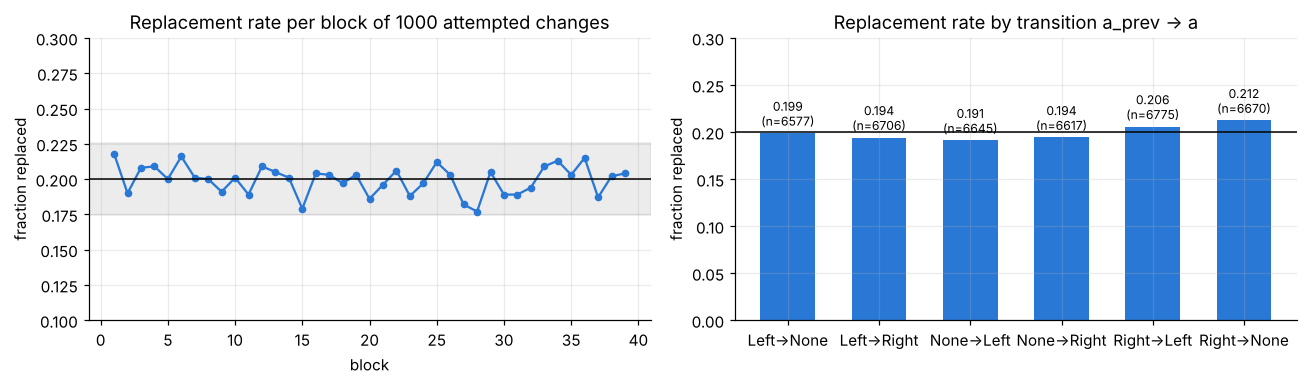

In [8]:
def plot_sticky_rate(trace, block=1000):
    """Plot the block-wise replacement rate and the per-transition replacement rate."""
    ch = trace[trace["a"] != trace["a_prev"]].copy()
    ch["stuck"] = (ch["a_exec"] != ch["a"]).astype(float)
    blocks = ch["stuck"].values[: len(ch) // block * block].reshape(-1, block).mean(axis=1)
    sd = np.sqrt(0.2 * 0.8 / block)

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(np.arange(1, len(blocks) + 1), blocks, "o-", color=ALGO_COLOR["Q-learning"], ms=4, lw=1.5)
    ax[0].axhline(0.2, color="k", lw=1); ax[0].axhspan(0.2 - 2 * sd, 0.2 + 2 * sd, color="grey", alpha=0.15)
    ax[0].set(title=f"Replacement rate per block of {block} attempted changes",
              xlabel="block", ylabel="fraction replaced", ylim=(0.1, 0.3))

    per = ch.groupby(["a_prev", "a"])["stuck"].agg(["mean", "size"]).reset_index()
    labels = [f"{ACTION_NAMES[p]}→{ACTION_NAMES[a]}" for p, a in zip(per["a_prev"], per["a"])]
    ax[1].bar(labels, per["mean"], color=ALGO_COLOR["Q-learning"], width=0.6)
    ax[1].axhline(0.2, color="k", lw=1)
    for i, (m, n) in enumerate(zip(per["mean"], per["size"])):
        ax[1].text(i, m + 0.005, f"{m:.3f}\n(n={n})", ha="center", va="bottom", fontsize=8)
    ax[1].set(title="Replacement rate by transition a_prev → a", ylabel="fraction replaced", ylim=(0, 0.3))
    plt.tight_layout(); plt.show()

plot_sticky_rate(trace)

### a.6 Test 5 – the gentle-arrival bonus
A random policy almost never reaches the flag, so this cell uses **two hand-coded policies**:

* **`push_with_velocity`**: push in the direction of the velocity (reaches the flag fast, usually *above* 0.04);
* **`brake_near_flag`**: the same, but stop pushing right once `x > 0.25` and `v > 0.03`. This is meant to produce *slower* arrivals.

Both run 100 episodes each in the modified environment. For **every step** the cell checks that `B = 20` exactly when the four conditions hold, and `B = 0` otherwise (including truncations and fast arrivals). The table counts arrivals, gentle arrivals and bonuses. The histogram shows arrival velocities against the 0.04 threshold.

,steps,episodes,arrivals,truncations,gentle_arrivals,fast_arrivals,bonuses_awarded,bonus_mismatches
policy,,,,,,,,
push_with_velocity,12064,100,100,0,31,69,31,0
brake_near_flag,12104,100,100,0,56,44,56,0


Bonus awarded on every gentle arrival and on nothing else (0 mismatches over all steps).


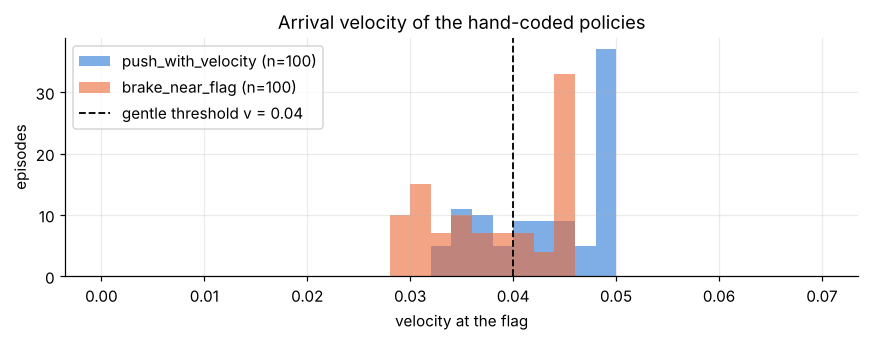

In [9]:
def push_with_velocity(obs):
    """Hand-coded policy: accelerate in the direction the car is already moving."""
    return 2 if obs[1] >= 0 else 0

def brake_near_flag(obs):
    """Hand-coded policy: like push_with_velocity, but coast when close to the flag and already fast."""
    if obs[0] > 0.25 and obs[1] > 0.03:
        return 1
    return 2 if obs[1] >= 0 else 0

def verify_bonus(policy, n_episodes=100, seed=CFG["seed"]):
    """Run a hand-coded policy, check B against the gentle-arrival rule on every step, return a summary."""
    env = make_env(modified=True, seed=seed, record_trace=True)
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        while True:
            obs, _, te, tr, _ = env.step(policy(obs))
            if te or tr:
                break
    t = pd.DataFrame(env._trace); env.close()
    rule = t["terminated"] & ~t["truncated"] & (t["pos"] >= FLAG_POS) & (t["vel"] <= GENTLE_VMAX)
    expected_B = np.where(rule, GENTLE_BONUS, 0.0)
    arrivals = t[t["terminated"]]
    summary = dict(policy=policy.__name__, steps=len(t), episodes=n_episodes,
                   arrivals=len(arrivals), truncations=int(t["truncated"].sum()),
                   gentle_arrivals=int(rule.sum()), fast_arrivals=int((arrivals["vel"] > GENTLE_VMAX).sum()),
                   bonuses_awarded=int((t["bonus"] > 0).sum()),
                   bonus_mismatches=int((t["bonus"] != expected_B).sum()))
    return summary, arrivals["vel"].values

rows, vels = [], {}
for pol in (push_with_velocity, brake_near_flag):
    s, v = verify_bonus(pol); rows.append(s); vels[pol.__name__] = v
bonus_table = pd.DataFrame(rows).set_index("policy")
display(bonus_table)
assert (bonus_table["bonus_mismatches"] == 0).all()
assert (bonus_table["bonuses_awarded"] == bonus_table["gentle_arrivals"]).all()
print("Bonus awarded on every gentle arrival and on nothing else (0 mismatches over all steps).")

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(0, 0.07, 36)
for (name, v), c in zip(vels.items(), ALGO_COLOR.values()):
    ax.hist(v, bins=bins, alpha=0.6, color=c, label=f"{name} (n={len(v)})")
ax.axvline(GENTLE_VMAX, color="k", lw=1.2, ls="--", label="gentle threshold v = 0.04")
ax.set(title="Arrival velocity of the hand-coded policies", xlabel="velocity at the flag", ylabel="episodes")
ax.legend(); plt.tight_layout(); plt.show()

**Summary of part (a).** The five tests show that the wrapper:

* reproduces the specification's worked example exactly;
* leaves the spaces, `info` and the dynamics untouched once its three modifications are switched off;
* blocks about 20 % of attempted action changes and never blocks a repeated action;
* charges the energy penalty on the *selected* action only;
* pays the +20 bonus on exactly the gentle arrivals.

---
## (b) Q-learning

### b.1 State discretiser and the fixed validation set
`Discretizer` maps the continuous `(position, velocity)` observation to a pair of integer bin indices on a uniform grid over the full observation box: position in [−1.2, 0.6] and velocity in [−0.07, 0.07]. Out-of-range values are clipped into the edge bins.

`make_validation_states` samples **500 states uniformly from the observation box once**, with a fixed seed. This set never changes during training. All four agents use the same set for the average-max-Q curve in part (d).

In [10]:
class Discretizer:
    """Uniform grid discretiser for the 2-D MountainCar observation."""

    def __init__(self, low, high, n_bins):
        """low/high: observation-space bounds; n_bins: (position bins, velocity bins)."""
        self.low = np.asarray(low, dtype=np.float64)
        self.high = np.asarray(high, dtype=np.float64)
        self.n_bins = np.asarray(n_bins, dtype=np.int64)
        self.width = (self.high - self.low) / self.n_bins          # width of one bin per dimension

    def __call__(self, obs):
        """Return the (pos_idx, vel_idx) tuple of one observation."""
        idx = ((np.asarray(obs) - self.low) / self.width).astype(np.int64)
        idx = np.clip(idx, 0, self.n_bins - 1)                     # clip boundary values into edge bins
        return int(idx[0]), int(idx[1])

    def batch(self, obs_array):
        """Vectorised version: (N,2) observations -> (N,) position indices and (N,) velocity indices."""
        idx = ((np.asarray(obs_array) - self.low) / self.width).astype(np.int64)
        idx = np.clip(idx, 0, self.n_bins - 1)
        return idx[:, 0], idx[:, 1]

    def centres(self):
        """Bin centres along each dimension (used for the policy heatmaps)."""
        return [self.low[d] + (np.arange(self.n_bins[d]) + 0.5) * self.width[d] for d in range(2)]


def make_validation_states(n, seed):
    """Sample n states uniformly from the MountainCar observation box (done once, before training)."""
    space = gym.make("MountainCar-v0").observation_space
    rng = np.random.default_rng(seed)
    return rng.uniform(space.low, space.high, size=(n, 2))

OBS_SPACE = gym.make("MountainCar-v0").observation_space
DISC = Discretizer(OBS_SPACE.low, OBS_SPACE.high, (CFG["n_pos_bins"], CFG["n_vel_bins"]))
VAL_STATES = make_validation_states(CFG["n_val_states"], CFG["seed"] + 1)
VAL_IDX = DISC.batch(VAL_STATES)                  # pre-computed bin indices of the validation set
print("Bin widths  (position, velocity):", DISC.width)
print("Validation set shape:", VAL_STATES.shape, "| first 3 states:\n", VAL_STATES[:3])

Bin widths  (position, velocity): [0.09  0.007]
Validation set shape: (500, 2) | first 3 states:
 [[-0.02586133 -0.06387145]
 [-1.16394679  0.04748976]
 [-0.14314252 -0.03854127]]


### b.2 Agent classes: one base class, two TD targets
To make sure **the TD target is the only difference** between the algorithms, both agents share one base class, `TabularTDAgent`. It owns:

* the Q-table of shape (20 × 20 × 3), initialised to zero;
* the ε-greedy action selection (ties broken at random, so the all-zero initial table does not bias towards action 0);
* the update `Q(s,a) ← Q(s,a) + α (target − Q(s,a))`.

Subclasses override **one method only**, `td_target`.

**Q-learning (off-policy):** `target = R + γ · max_a' Q(s', a')`, and just `R` when the episode **terminated**. A **truncated** episode is *not* terminal, so it still bootstraps.

The `a` that gets updated is the action the agent **selected**. The executed action is hidden from it.

In [11]:
class TabularTDAgent:
    """Base class: Q-table, epsilon-greedy policy and the generic TD update. Subclasses define td_target."""

    name = "TD"

    def __init__(self, n_bins, n_actions, alpha, gamma, seed):
        self.Q = np.zeros((*n_bins, n_actions))       # Q-table initialised to zero
        self.n_actions = n_actions
        self.alpha, self.gamma = alpha, gamma
        self.rng = np.random.default_rng(seed)       # agent's own RNG (exploration + tie-breaking)
        self.N = np.zeros(self.Q.shape, dtype=np.int64)  # visit counts per (s,a), used only for plots

    def greedy(self, s):
        """Greedy action in discrete state s, breaking ties uniformly at random."""
        q = self.Q[s]
        best = np.flatnonzero(q == q.max())
        return int(best[0]) if len(best) == 1 else int(self.rng.choice(best))

    def act(self, s, epsilon):
        """Epsilon-greedy action selection."""
        if self.rng.random() < epsilon:
            return int(self.rng.integers(self.n_actions))
        return self.greedy(s)

    def td_target(self, r, s_next, a_next, terminated):
        """Return the TD target. Implemented by the subclasses (the only algorithmic difference)."""
        raise NotImplementedError

    def update(self, s, a, r, s_next, a_next, terminated):
        """Apply Q(s,a) <- Q(s,a) + alpha * (target - Q(s,a)) and return the TD error."""
        td_error = self.td_target(r, s_next, a_next, terminated) - self.Q[s][a]
        self.Q[s][a] += self.alpha * td_error
        self.N[s][a] += 1                              # bookkeeping for the visitation heatmaps
        return td_error


class QLearningAgent(TabularTDAgent):
    """Off-policy TD control: bootstraps from the greedy (max) action in s'."""

    name = "Q-learning"

    def td_target(self, r, s_next, a_next, terminated):
        """R + gamma * max_a' Q(s',a'); no bootstrap on a true termination (truncation still bootstraps)."""
        if terminated:
            return r
        return r + self.gamma * self.Q[s_next].max()

print("TabularTDAgent and QLearningAgent defined.")

TabularTDAgent and QLearningAgent defined.


### b.3 Justifying the bin count (20 × 20)
The assignment asks for at least 20 × 20 bins, with the choice justified. This cell runs a short **bin-size study** on the *modified* environment: Q-learning for 3 000 episodes with 20, 30 and 40 bins per dimension, all other settings unchanged.

Finer grids describe the state more precisely, but each cell is visited less often. With a few thousand episodes the coarser grid learns faster, and it is still fine enough to separate the "brake" and "push" regions near the flag. That is why 20 × 20 is used for the main experiments. The training loop used here is defined in the next section, so this cell runs after it. See **Training → bin study**.

---
## (c) SARSA

### c.1 SARSA agent
`SarsaAgent` inherits **everything** from `TabularTDAgent` (Q-table, ε-greedy policy, update rule, RNG handling) and overrides only `td_target`.

**SARSA (on-policy):** `target = R + γ · Q(s', a')`, where `a'` is the next action **actually chosen by the ε-greedy policy**. On termination the target is just `R`.

Because the training loop below always chooses `a'` with ε-greedy before the update, for **both** agents, the two runs consume random numbers in exactly the same pattern. The TD target really is the only difference.

In [12]:
class SarsaAgent(TabularTDAgent):
    """On-policy TD control: bootstraps from the action a' actually chosen by the epsilon-greedy policy."""

    name = "SARSA"

    def td_target(self, r, s_next, a_next, terminated):
        """R + gamma * Q(s',a'); no bootstrap on a true termination (truncation still bootstraps)."""
        if terminated:
            return r
        return r + self.gamma * self.Q[s_next][a_next]

AGENT_CLASSES = {"Q-learning": QLearningAgent, "SARSA": SarsaAgent}
print("SarsaAgent defined. Algorithms:", list(AGENT_CLASSES))

SarsaAgent defined. Algorithms: ['Q-learning', 'SARSA']


---
## Training (shared by parts b, c, d)

### T.1 Exploration schedule and the shared training loop
`epsilon_at` implements the exponential decay stated in Section 0.3.

`train_agent` is the **single** training loop used for all four runs. Per episode it:

1. resets the environment. Episode 0 is seeded with the global seed, which also seeds the wrapper's sticky RNG;
2. picks `a` ε-greedily, then repeatedly steps, picks `a'` ε-greedily in `s'`, updates `Q(s,a)` and moves on with `(s, a) ← (s', a')`;
3. records the per-episode metrics needed in part (d): episode reward, success (terminated at the flag), gentle arrival (terminated with `v ≤ 0.04`, measured from the observation so it is also defined for the original environment), number of **selected** push actions, episode length, arrival velocity, and the **average of max_a Q(s,a) over the fixed validation set**. It also records three extra diagnostics used in d.8: the mean |TD error| per step, the number of times the agent **changes** its selected action, and the number of blocked changes. The blocked-change count is read from the wrapper's private counter for analysis only and is never used in learning.

The optional arguments `seed`, `stick_prob` and `oracle` keep their main-experiment defaults. Only Section X changes them.

It prints one progress line every `log_every` episodes, with 100-episode moving averages. The complete per-episode history is returned as a DataFrame.

In [13]:
def epsilon_at(episode, cfg=CFG):
    """Exponentially decayed exploration rate for a given episode index."""
    decay_episodes = cfg["eps_decay_frac"] * cfg["n_episodes"]
    eps = cfg["eps_start"] * (cfg["eps_min"] / cfg["eps_start"]) ** (episode / decay_episodes)
    return max(cfg["eps_min"], eps)


def build_state_fn(disc, env, oracle):
    """Return a function obs -> discrete state.

    Blind agents (the graded ones) see only the binned (position, velocity).
    The oracle agent (Section X.3, analysis only) additionally sees the wrapper's a_prev.
    """
    if oracle:
        return lambda obs: disc(obs) + (env.a_prev,)
    return disc


def train_agent(algo, modified, cfg=CFG, n_episodes=None, n_bins=None, verbose=True,
                seed=None, stick_prob=STICK_PROB, oracle=False, log_every=None):
    """Train one agent ('Q-learning' or 'SARSA') on the original or modified env.

    seed / stick_prob / oracle default to the main experiment and are only changed in Section X.
    Returns (agent, history DataFrame with one row per training episode).
    """
    n_episodes = n_episodes or cfg["n_episodes"]
    n_bins = n_bins or (cfg["n_pos_bins"], cfg["n_vel_bins"])
    seed = cfg["seed"] if seed is None else seed
    log_every = log_every or cfg["log_every"]
    disc = Discretizer(OBS_SPACE.low, OBS_SPACE.high, n_bins)
    val_idx = disc.batch(VAL_STATES)
    env = (StickyActuatorMountainCar(gym.make("MountainCar-v0"), stick_prob=stick_prob, seed=seed)
           if modified else gym.make("MountainCar-v0"))
    state_fn = build_state_fn(disc, env, oracle and modified)
    q_shape = tuple(n_bins) + ((3,) if (oracle and modified) else ())   # oracle adds an a_prev axis
    agent = AGENT_CLASSES[algo](q_shape, env.action_space.n, cfg["alpha"], cfg["gamma"], seed)
    label = f"{algo:<10} | {'Modified' if modified else 'Original'}" + (" | oracle" if oracle else "") \
            + (f" | p={stick_prob}" if modified and stick_prob != STICK_PROB else "") + (f" | seed={seed}" if seed != cfg["seed"] else "")
    hist, t0 = [], time.time()

    for ep in range(n_episodes):
        eps = epsilon_at(ep, cfg)
        obs, _ = env.reset(seed=seed if ep == 0 else None)          # seed once, then continue the stream
        s = state_fn(obs)
        a = agent.act(s, eps)
        ep_reward, pushes, length, switches, td_abs = 0.0, 0, 0, 0, 0.0
        while True:
            obs_next, r, terminated, truncated, _ = env.step(a)
            s_next = state_fn(obs_next)
            a_next = agent.act(s_next, eps)                         # chosen for both algorithms
            td_abs += abs(agent.update(s, a, r, s_next, a_next, terminated))   # only td_target differs
            ep_reward += r; pushes += int(a != 1); length += 1
            switches += int(a_next != a)                            # how often the agent changes its command
            s, a = s_next, a_next
            if terminated or truncated:
                break

        hist.append(dict(episode=ep, epsilon=eps, reward=ep_reward, length=length, pushes=pushes,
                         success=int(terminated),
                         gentle=int(terminated and obs_next[1] <= GENTLE_VMAX),
                         arrival_v=float(obs_next[1]) if terminated else np.nan,
                         switches=switches,
                         stuck=getattr(env, "_episode_stuck", 0),   # analysis only (0 for the original env)
                         td_abs=td_abs / length,                    # mean |TD error| per step
                         avg_max_q=float(agent.Q[val_idx[0], val_idx[1]].max(axis=-1).mean())))

        # Progress log with 100-episode moving averages
        if verbose and ((ep + 1) % log_every == 0 or ep == 0):
            w = hist[-cfg["ma_window"]:]
            print(f"[{label}] ep {ep+1:5d} | eps {eps:.3f} | R {ep_reward:8.2f} | "
                  f"MA100 R {np.mean([h['reward'] for h in w]):8.2f} | "
                  f"succ {np.mean([h['success'] for h in w]):.2f} | gentle {np.mean([h['gentle'] for h in w]):.2f} | "
                  f"push {np.mean([h['pushes'] for h in w]):6.1f} | len {np.mean([h['length'] for h in w]):6.1f} | "
                  f"avg maxQ {hist[-1]['avg_max_q']:8.2f}")
    env.close()
    if verbose:
        print(f"[{label}] finished {n_episodes} episodes in {time.time() - t0:.1f} s")
    agent.disc, agent.oracle = disc, (oracle and modified)
    return agent, pd.DataFrame(hist)

print("epsilon at episodes 0 / 1000 / 2000 / 3600 / 5999:",
      [round(epsilon_at(e), 4) for e in (0, 1000, 2000, 3600, 5999)])

epsilon at episodes 0 / 1000 / 2000 / 3600 / 5999: [1.0, 0.2783, 0.0774, 0.01, 0.01]


### T.2 Bin study (justification for part b.3)
This cell runs the bin-size study described in b.3: Q-learning on the **modified** environment, 3 000 episodes, with 20 × 20, 30 × 30 and 40 × 40 grids. Logging is switched off here. Only the final 500-episode averages are reported.

In [14]:
bin_rows = []
for nb in (20, 30, 40):
    _, h = train_agent("Q-learning", modified=True, n_episodes=3000, n_bins=(nb, nb), verbose=False)
    last = h.tail(500)
    bin_rows.append(dict(bins=f"{nb}x{nb}", states=nb * nb,
                         first_success_episode=int(h.index[h["success"] == 1][0]) if h["success"].any() else None,
                         success_rate_last500=last["success"].mean(),
                         gentle_rate_last500=last["gentle"].mean(),
                         mean_reward_last500=last["reward"].mean()))
    print(f"{nb}x{nb} done:", datetime.datetime.now().strftime("%H:%M:%S"))
bin_table = pd.DataFrame(bin_rows).set_index("bins")
display(bin_table)

20x20 done: 08:22:08


30x30 done: 08:22:23


40x40 done: 08:22:37


,states,first_success_episode,success_rate_last500,gentle_rate_last500,mean_reward_last500
bins,,,,,
20x20,400,985,0.782,0.782,-183.5424
30x30,900,1133,0.284,0.284,-215.3088
40x40,1600,1585,0.038,0.038,-225.2832


**Bin-study result (justification of 20 × 20).** With the same 3 000-episode budget, the 20 × 20 grid reaches the flag first (episode 985) and succeeds in **78 %** of its last 500 episodes. 30 × 30 (900 states) reaches only 28 %, and 40 × 40 (1 600 states) 4 %. Every extra bin divides the same experience among more cells, so the value information from the rare early successes spreads backwards more slowly. 20 × 20 bins are 0.09 wide in position and 0.007 in velocity, still fine enough to separate the braking band below v = 0.04 near the flag. It is therefore the smallest allowed grid and the best one for this training budget. (The same sample-budget effect reappears in the oracle experiment, X.3.)

### T.3 Training the four agents
This cell trains all four agents **with identical settings** (`CFG`) and prints the progress log every 100 episodes. The full per-episode history of every run is kept in `HIST` and saved to `training_history.csv` for reproducibility.

In [15]:
AGENTS, HIST = {}, {}
for env_name, modified in (("Original", False), ("Modified", True)):
    for algo in ("Q-learning", "SARSA"):
        key = (algo, env_name)
        print("=" * 150)
        print(f"Training {algo} on the {env_name} environment  (started {datetime.datetime.now():%H:%M:%S})")
        AGENTS[key], HIST[key] = train_agent(algo, modified)

all_hist = pd.concat({f"{a} | {e}": h for (a, e), h in HIST.items()}, names=["run"]).reset_index(level=0)
all_hist.to_csv("training_history.csv", index=False)
print("Saved per-episode history of all runs to training_history.csv:", all_hist.shape)

Training Q-learning on the Original environment  (started 08:22:37)
[Q-learning | Original] ep     1 | eps 1.000 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  145.0 | len  200.0 | avg maxQ    -0.01


[Q-learning | Original] ep   100 | eps 0.881 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  135.0 | len  200.0 | avg maxQ    -0.82


[Q-learning | Original] ep   200 | eps 0.775 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  138.4 | len  200.0 | avg maxQ    -1.45


[Q-learning | Original] ep   300 | eps 0.682 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  139.9 | len  200.0 | avg maxQ    -2.16


[Q-learning | Original] ep   400 | eps 0.600 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  140.5 | len  200.0 | avg maxQ    -2.91


[Q-learning | Original] ep   500 | eps 0.528 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  141.4 | len  200.0 | avg maxQ    -3.78


... (225 outputs left out)

[SARSA      | Modified] ep  5700 | eps 0.010 | R  -114.60 | MA100 R  -156.43 | succ 0.97 | gentle 0.97 | push  102.6 | len  155.1 | avg maxQ   -26.55


[SARSA      | Modified] ep  5800 | eps 0.010 | R  -106.60 | MA100 R  -138.91 | succ 1.00 | gentle 1.00 | push   99.7 | len  139.0 | avg maxQ   -26.49


[SARSA      | Modified] ep  5900 | eps 0.010 | R  -198.40 | MA100 R  -155.56 | succ 0.95 | gentle 0.95 | push  104.8 | len  153.6 | avg maxQ   -26.43


[SARSA      | Modified] ep  6000 | eps 0.010 | R  -153.40 | MA100 R  -174.56 | succ 0.84 | gentle 0.84 | push  107.2 | len  169.9 | avg maxQ   -26.57
[SARSA      | Modified] finished 6000 episodes in 27.1 s
Saved per-episode history of all runs to training_history.csv: (24000, 13)


---
## (d) Performance Evaluation

### d.0 Plotting helpers
`moving_average` computes a trailing 100-episode mean. `plot_metric` draws one metric for all four runs, using one colour per **algorithm** (blue = Q-learning, orange = SARSA) and one line style per **environment** (dashed = original, solid = modified). Each run is also labelled in the legend, so colour is never the only cue.

In [16]:
def moving_average(x, w=CFG["ma_window"]):
    """Trailing moving average over the previous w episodes (shorter window at the start)."""
    return pd.Series(x).rolling(w, min_periods=1).mean().values


def plot_metric(ax, column, title, ylabel, envs=("Original", "Modified"), raw=False):
    """Plot the 100-episode moving average of `column` for every (algorithm, environment) run."""
    for (algo, env_name), h in HIST.items():
        if env_name not in envs:
            continue
        if raw:
            ax.plot(h["episode"], h[column], color=ALGO_COLOR[algo], alpha=0.12, lw=0.5)
        ax.plot(h["episode"], moving_average(h[column]), color=ALGO_COLOR[algo],
                ls=ENV_STYLE[env_name], lw=1.8, label=f"{algo} – {env_name}")
    ax.set(title=title, xlabel="training episode", ylabel=ylabel)
    ax.legend(fontsize=8)

print("Plot helpers ready.")

Plot helpers ready.


### d.1 Episode reward vs training episode (100-episode moving average)
The two environments use **different reward scales**: −1 per step in the original, and −1 − 0.2 per selected push + 20 on a gentle arrival in the modified one. So they get separate panels rather than a shared axis. The faint lines are the raw per-episode rewards.

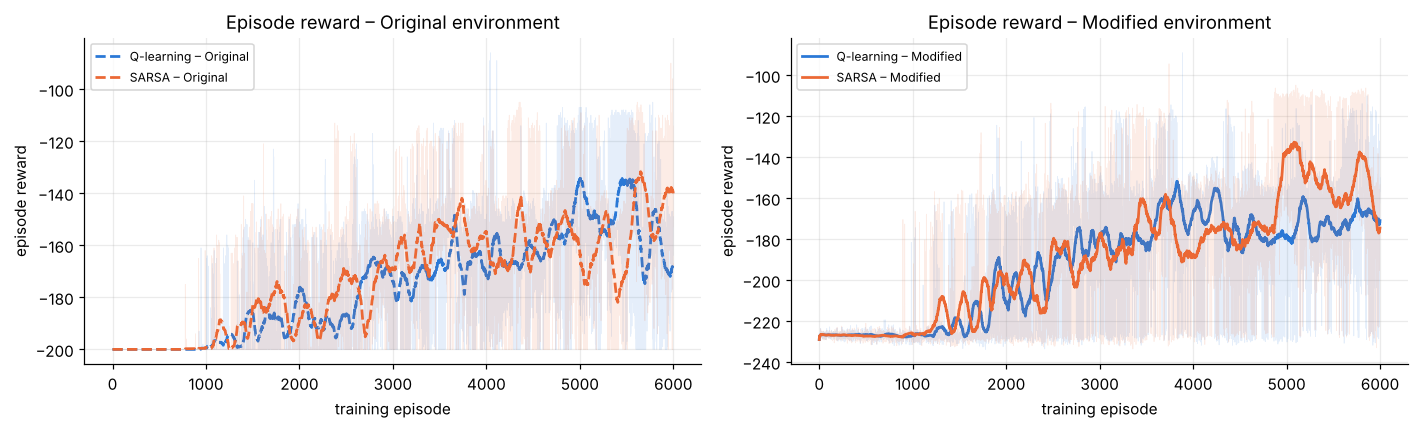

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_metric(ax[0], "reward", "Episode reward – Original environment", "episode reward", envs=("Original",), raw=True)
plot_metric(ax[1], "reward", "Episode reward – Modified environment", "episode reward", envs=("Modified",), raw=True)
plt.tight_layout(); plt.show()

**Interpretation.**

* **Original environment.** Both agents stay at −200 (every episode truncated) until about episode 1 000. ε is still about 0.28 there, and the zero-initialised Q-table (optimistic, since all true values are negative) has driven enough exploration for the first lucky arrivals to start propagating value backwards. The moving averages then climb unevenly to about −140 to −170. Q-learning and SARSA move in lockstep for most of training, with neither clearly ahead. The curves stay noisy even at ε = 0.01, because one greedy change in a 20 × 20 cell can switch whole groups of episodes between "one swing" and "two swings" to the flag.
* **Modified environment.** The curves start lower, at about −227: −200 for truncation plus −0.2 × about 135 random pushes. Learning begins at about the same point (episodes 1 200–1 300). Every successful episode in this environment ends with the +20 gentle-arrival bonus (see d.3). So the gain from learning is larger than the shorter episodes alone would suggest. In the last 1 000 episodes SARSA averages −153.0 and Q-learning −171.5. SARSA's peak (about −133 near episode 5 000) is the best of the four runs, but it also swings more.
* The two panels use **different reward functions**, so their absolute values must not be compared directly. Success, gentle-arrival and episode-length metrics (d.3, d.6) are the fair comparison across environments.

### d.2 Average predicted value, mean over validation states of max_a Q(s,a)
The left panel shows the average of max_a Q(s,a) over the fixed 500-state validation set for all four runs. The right panel shows the **gap** (Q-learning − SARSA) for each environment. Discussion question 1 is answered from this gap.

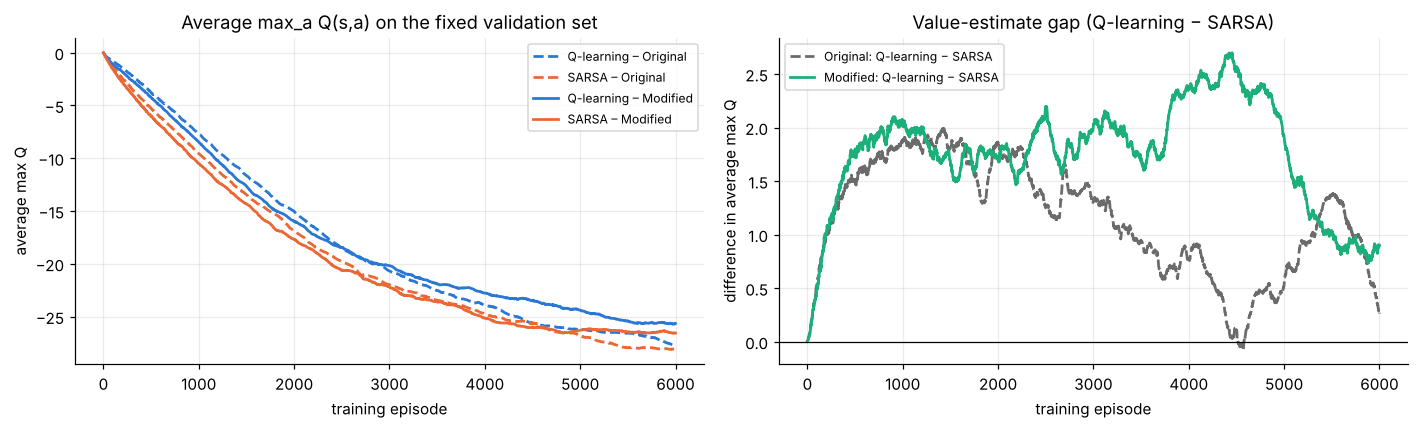

,gap_mean_last1000,abs_gap_mean_all,QL_final,SARSA_final
environment,,,,
Original,0.9585,1.1567,-27.844,-28.1135
Modified,1.0998,1.7578,-25.665,-26.5678


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (algo, env_name), h in HIST.items():
    ax[0].plot(h["episode"], h["avg_max_q"], color=ALGO_COLOR[algo], ls=ENV_STYLE[env_name], lw=1.8,
               label=f"{algo} – {env_name}")
ax[0].set(title="Average max_a Q(s,a) on the fixed validation set", xlabel="training episode", ylabel="average max Q")
ax[0].legend(fontsize=8)

gap_rows = []
for env_name, c in (("Original", "#6b6b6b"), ("Modified", "#1baf7a")):
    gap = HIST[("Q-learning", env_name)]["avg_max_q"].values - HIST[("SARSA", env_name)]["avg_max_q"].values
    ax[1].plot(gap, color=c, ls=ENV_STYLE[env_name], lw=1.8, label=f"{env_name}: Q-learning − SARSA")
    gap_rows.append(dict(environment=env_name,
                         gap_mean_last1000=gap[-1000:].mean(),
                         abs_gap_mean_all=np.abs(gap).mean(),
                         QL_final=HIST[("Q-learning", env_name)]["avg_max_q"].iloc[-1],
                         SARSA_final=HIST[("SARSA", env_name)]["avg_max_q"].iloc[-1]))
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(title="Value-estimate gap (Q-learning − SARSA)", xlabel="training episode", ylabel="difference in average max Q")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
gap_table = pd.DataFrame(gap_rows).set_index("environment"); display(gap_table)

**Interpretation.**

* All four average-max-Q curves fall steadily from the optimistic initial value of 0 towards the true (negative) values. They are **still falling slowly at episode 6 000**, so none of the value functions has fully converged (see the limitation in e.5).
* **Q-learning's estimate is above SARSA's in both environments for almost all of training.** That is what the targets predict: `max_a' Q(s',a')` ≥ `Q(s',a')` for the ε-greedy `a'`. SARSA's target also includes the cost of exploratory actions, and Q-learning's `max` is optimistically biased.
* **The gap is larger with the sticky actuator.** Averaged over all of training, |gap| is 1.76 in the modified environment against 1.16 in the original (about 50 % larger). Its peak is about 2.7 against about 1.9. In the original environment the gap shrinks after about episode 2 500 and briefly reaches 0 near episode 4 500. In the modified environment it stays near 2 until about episode 5 000.
* In the last 1 000 episodes, with ε fixed at 0.01, the gaps converge (1.10 vs 0.96). With so little exploration, SARSA's sampled `a'` is nearly always the greedy action, so the two targets almost coincide.

### d.3 Success rate and gentle-arrival rate (100-episode moving average)
**Success** means the episode terminated at the flag. A **gentle arrival** is a success with arrival velocity ≤ 0.04. Gentle arrivals are measured in the original environment too, even though nothing rewards them there. That gives a baseline for how often gentle arrivals happen without any incentive.

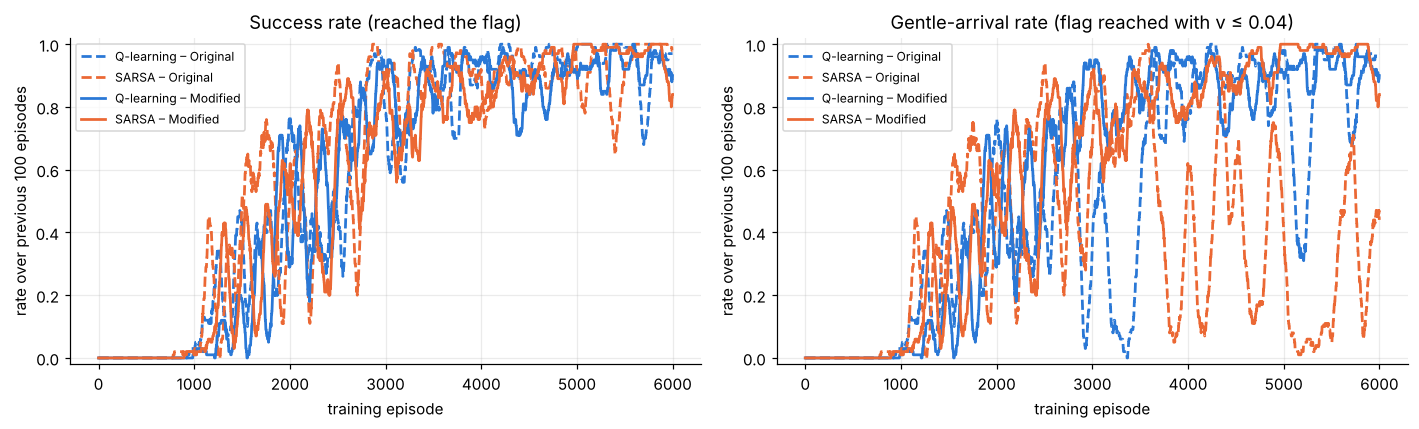

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_metric(ax[0], "success", "Success rate (reached the flag)", "rate over previous 100 episodes")
plot_metric(ax[1], "gentle", "Gentle-arrival rate (flag reached with v ≤ 0.04)", "rate over previous 100 episodes")
for a in ax: a.set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()

**Interpretation.**

* **Success rate:** all four agents go from 0 to more than 0.8 between episodes 1 000 and 3 000, then stay mostly at 0.85–1.0 with occasional dips. The episode at which the 100-episode success rate first reaches 0.5 is about 1 500 for SARSA on the original environment and about 1 850–1 950 for the other three. So the sticky actuator does **not** noticeably slow down learning to reach the flag. Over the last 1 000 episodes the success rates are 0.95 (QL-orig), 0.94 (SARSA-orig), 0.93 (QL-mod) and 0.97 (SARSA-mod).
* **Gentle-arrival rate:** this is where the environments differ sharply. In the **modified** environment the gentle-arrival curve sits **on top of** the success curve once learning has started: practically every arrival is gentle (100 % of arrivals in the last 1 000 episodes for both agents). In the **original** environment the gentle rate swings between almost 0 and almost 1 even though success stays high. Arrival speed is not rewarded there, so small changes in the greedy policy near the flag move the arrival velocity back and forth across 0.04. SARSA-original ends with only 24 % gentle arrivals over the last 1 000 episodes, against 82 % for Q-learning-original.

### d.4 Average number of push actions selected per episode
This counts the **selected** actions 0 or 2 per episode, which is what the energy penalty charges. The left panel shows the absolute count. Shorter episodes mechanically contain fewer pushes, so the right panel shows the **push fraction** (pushes ÷ episode length), which is independent of episode length.

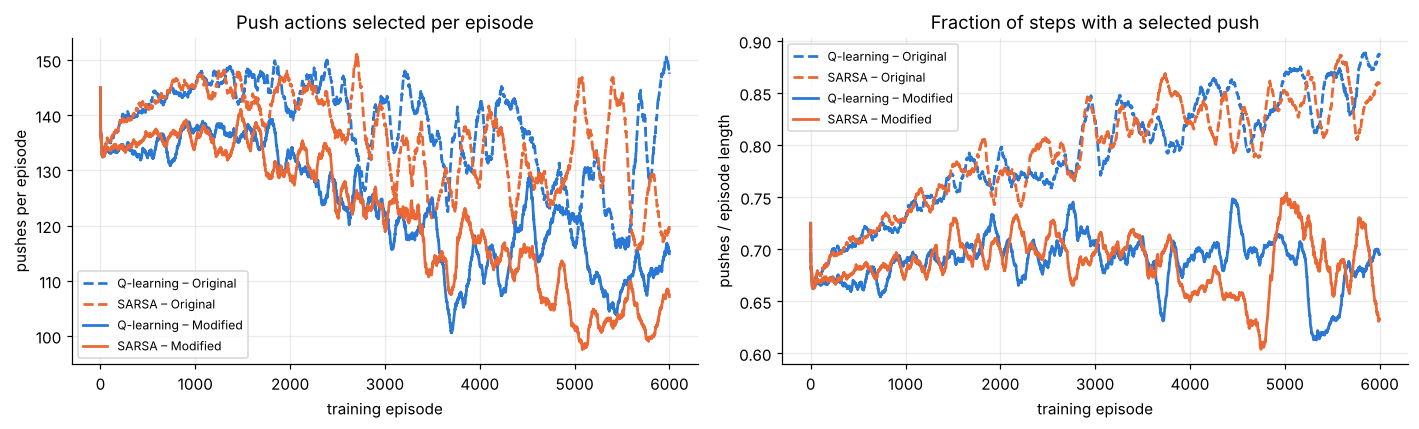

In [20]:
for h in HIST.values():
    h["push_frac"] = h["pushes"] / h["length"]          # fraction of steps with a selected push
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_metric(ax[0], "pushes", "Push actions selected per episode", "pushes per episode")
plot_metric(ax[1], "push_frac", "Fraction of steps with a selected push", "pushes / episode length")
plt.tight_layout(); plt.show()

**Interpretation.**

* At the start every agent pushes on about 2/3 of the steps, as expected from a uniformly random policy. In the **original** environment the push **fraction rises steadily to about 0.85–0.89**. With no cost on pushing, the agents learn the "always pump energy" solution, and the only thing that reduces the absolute push count is the shorter episodes.
* In the **modified** environment the push fraction **never rises**: it stays around 0.62–0.75 (0.66 for Q-learning and 0.69 for SARSA in the last 1 000 episodes). The absolute count falls to about 103 (SARSA) and 111 (Q-learning) pushes per episode, against about 130 for both agents in the original. So the energy penalty works: the agents select "None" on roughly a third of the steps and accept slightly longer episodes in return.
* SARSA reaches the lowest push counts (about 100 around episode 5 000), in line with its on-policy, cost-aware targets. The difference from Q-learning is small compared with the difference between the environments.

### d.5 Greedy policy maps
For each agent, this plots the greedy action `argmax_a Q(s,a)` on the 20 × 20 position × velocity grid. Cells that were **never updated** (all three Q-values still 0) are shown in white, because their "greedy action" is meaningless. The dashed vertical line marks the flag (x = 0.5). The dotted horizontal line marks the gentle-arrival speed (v = 0.04).

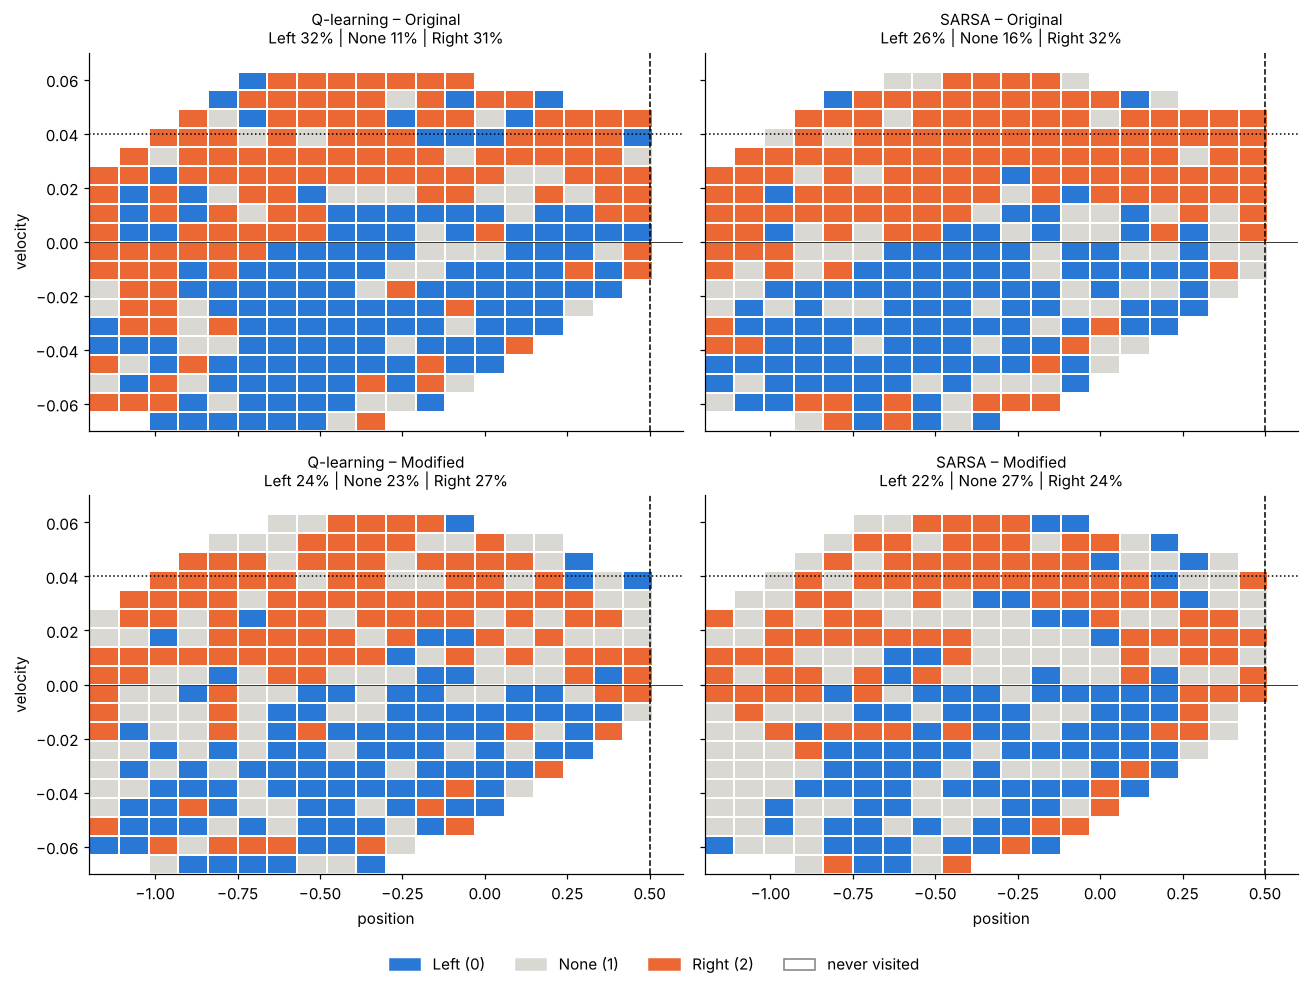

In [21]:
def policy_grid(agent):
    """Greedy action per grid cell, with NaN for cells whose Q-values were never updated."""
    g = agent.Q.argmax(axis=2).astype(float)
    g[np.all(agent.Q == 0, axis=2)] = np.nan
    return g

POLICY_CMAP = ListedColormap(["#2a78d6", "#d9d8d3", "#eb6834"])     # Left / None / Right
pos_c, vel_c = DISC.centres()
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, key in zip(axes.flat, [("Q-learning", "Original"), ("SARSA", "Original"),
                               ("Q-learning", "Modified"), ("SARSA", "Modified")]):
    g = policy_grid(AGENTS[key])
    ax.pcolormesh(pos_c, vel_c, g.T, cmap=POLICY_CMAP, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3),
                  shading="nearest", edgecolors="white", linewidth=0.3)
    ax.axvline(FLAG_POS, color="k", ls="--", lw=1); ax.axhline(GENTLE_VMAX, color="k", ls=":", lw=1)
    ax.axhline(0, color="k", lw=0.5)
    share = {n: np.nanmean(g == i) for i, n in ACTION_NAMES.items()}
    ax.set_title(f"{key[0]} – {key[1]}\nLeft {share['Left']:.0%} | None {share['None']:.0%} | Right {share['Right']:.0%}",
                 fontsize=10)
    ax.grid(False)
for ax in axes[1]: ax.set_xlabel("position")
for ax in axes[:, 0]: ax.set_ylabel("velocity")
fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(POLICY_CMAP.colors, ["Left (0)", "None (1)", "Right (2)"])]
           + [Patch(facecolor="white", edgecolor="grey", label="never visited")],
           loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Interpretation.**

* All four maps show the classic MountainCar energy-pumping structure. **Left (blue) is chosen mostly in the lower half (v < 0)** and **Right (orange) in the upper half (v > 0)**, so the agent pushes in the direction of motion. The visited region has the familiar oval shape of reachable states. White corners (for example, high speed at the far left wall) are never visited.
* **Original environment:** "None" covers only 11 % (Q-learning) and 16 % (SARSA) of the visited cells, scattered with no clear pattern. These are mostly cells where the three Q-values are almost tied.
* **Modified environment:** "None" grows to **23 % (Q-learning) and 27 % (SARSA)**. It forms coherent regions: (i) near zero velocity at the far left, where a push gains little; (ii) the **coasting / braking zone near the flag** (x ≈ 0.1–0.45, v ≈ 0.02–0.05), where both modified agents mix "None" with a few "Left" cells, which avoids arriving faster than 0.04; and (iii) at very negative velocities, where gravity already does the work.
* The SARSA-modified map is the most fragmented (largest "None" share, scattered Left/Right islands). This fits its weaker greedy evaluation in d.6. With one seed and coarse bins, many cells are near-ties, and SARSA's ε-aware values do not always rank the greedy action correctly.

### d.6 Final greedy evaluation (ε = 0, 100 fixed-seed test episodes)
`evaluate_greedy` runs each trained agent with ε = 0 for 100 episodes. Episode *i* is reset with seed `10 000 + i`, which also re-seeds the sticky RNG in the modified environment, so every agent faces the same start states (and, in the modified environment, the same random number stream). Ties between equal Q-values are broken by the lowest index, so evaluation is deterministic.

Each agent is evaluated in **its own training environment**, which is the required table. As an extra robustness check, the original-trained agents are also evaluated in the modified environment and vice versa.

In [22]:
def evaluate_greedy(agent, modified, cfg=CFG, stick_prob=STICK_PROB):
    """Run the epsilon = 0 policy for n_test_episodes fixed-seed episodes and return summary metrics."""
    env = (StickyActuatorMountainCar(gym.make("MountainCar-v0"), stick_prob=stick_prob, seed=cfg["test_seed_base"])
           if modified else gym.make("MountainCar-v0"))
    state_fn = build_state_fn(agent.disc, env, getattr(agent, "oracle", False))
    rewards, succ, gentle, lengths, pushes, arr_v = [], [], [], [], [], []
    for i in range(cfg["n_test_episodes"]):
        obs, _ = env.reset(seed=cfg["test_seed_base"] + i)
        total, n, p = 0.0, 0, 0
        while True:
            a = int(np.argmax(agent.Q[state_fn(obs)]))             # deterministic greedy action
            obs, r, te, tr, _ = env.step(a)
            total += r; n += 1; p += int(a != 1)
            if te or tr:
                break
        rewards.append(total); lengths.append(n); pushes.append(p); succ.append(te)
        gentle.append(te and obs[1] <= GENTLE_VMAX); arr_v.append(obs[1] if te else np.nan)
    env.close()
    return dict(mean_reward=np.mean(rewards), std_reward=np.std(rewards),
                success_rate=np.mean(succ), gentle_arrival_rate=np.mean(gentle),
                mean_episode_length=np.mean(lengths), mean_pushes=np.mean(pushes),
                mean_arrival_velocity=np.nanmean(arr_v) if any(succ) else np.nan)

eval_rows, cross_rows = [], []
for (algo, env_name), agent in AGENTS.items():
    is_mod = env_name == "Modified"
    eval_rows.append(dict(agent=f"{algo} – {env_name}", **evaluate_greedy(agent, modified=is_mod)))
    cross_rows.append(dict(agent=f"{algo} – trained {env_name}", evaluated_in="Original" if is_mod else "Modified",
                           **evaluate_greedy(agent, modified=not is_mod)))
EVAL = pd.DataFrame(eval_rows).set_index("agent")
print("Greedy evaluation in each agent's own training environment (100 episodes, seeds 10000-10099):")
display(EVAL)
print("Cross-evaluation (agent tested in the *other* environment):")
display(pd.DataFrame(cross_rows).set_index("agent"))

Greedy evaluation in each agent's own training environment (100 episodes, seeds 10000-10099):


,mean_reward,std_reward,success_rate,gentle_arrival_rate,mean_episode_length,mean_pushes,mean_arrival_velocity
agent,,,,,,,
Q-learning – Original,-163.310,12.4793,1.00,1.00,163.31,143.61,0.0342
SARSA – Original,-129.740,24.5241,1.00,0.50,129.74,112.29,0.0349
Q-learning – Modified,-168.838,30.1185,0.91,0.91,164.56,110.39,0.0262
SARSA – Modified,-188.664,21.5302,0.75,0.75,182.48,105.92,0.0239


Cross-evaluation (agent tested in the *other* environment):


,evaluated_in,mean_reward,std_reward,success_rate,gentle_arrival_rate,mean_episode_length,mean_pushes,mean_arrival_velocity
agent,,,,,,,,
Q-learning – trained Original,Modified,-180.444,16.4156,1.00,0.60,163.57,144.37,0.0382
SARSA – trained Original,Modified,-140.504,37.2630,1.00,0.55,129.17,111.67,0.0351
Q-learning – trained Modified,Original,-162.600,21.7053,1.00,1.00,162.60,107.81,0.0249
SARSA – trained Modified,Original,-181.900,14.0886,0.77,0.77,181.90,105.73,0.0239


**Interpretation.**

* **Original environment:** both greedy agents succeed in **100 %** of the test episodes. SARSA is markedly faster (130 steps, reward −129.7) than Q-learning (163 steps, −163.3). Q-learning happens to arrive gently in 100 % of tests (mean arrival speed 0.034), SARSA in only 50 %. Nothing rewards gentleness in this environment, so this is a side effect of each policy, not a learned goal (see d.3).
* **Modified environment:** **Q-learning is the stronger final greedy policy**: 91 % success, all of it gentle, reward −168.8, 110 pushes. SARSA reaches only 75 % success and −188.7. Both arrive far more slowly than in the original (mean arrival speed 0.026 and 0.024, against about 0.034), and they push about 30 fewer times than Q-learning-original.
* **Cross-evaluation (extra):** Q-learning trained on the modified environment and tested on the original succeeds and arrives gently in 100 % of episodes with 108 pushes. The controlled behaviour carries over. The original-trained agents keep their 100 % success under sticky actuators, but only 55–60 % of their arrivals are gentle, because they were never taught to slow down.
* The greedy SARSA-modified result (75 %) is well below its own training success rate (97 % in the last 1 000 episodes, with ε = 0.01). It is a single snapshot taken during a dip (d.3). The multi-seed study in **X.1** shows that seed 42 is SARSA's *worst* seed: averaged over five seeds, SARSA-modified reaches 0.946 greedy success against 0.878 for Q-learning-modified. **This single-seed table should therefore not be used alone to rank the algorithms.**

### d.7 Arrival-speed statistics
This cell gathers arrival-velocity statistics, which discussion question 3 needs. It compares the **last 1 000 training episodes** of each run (the median arrival velocity and the share of arrivals at ≤ 0.04) with the greedy test episodes. The histogram shows the training arrivals over the last 1 000 episodes against the 0.04 threshold.

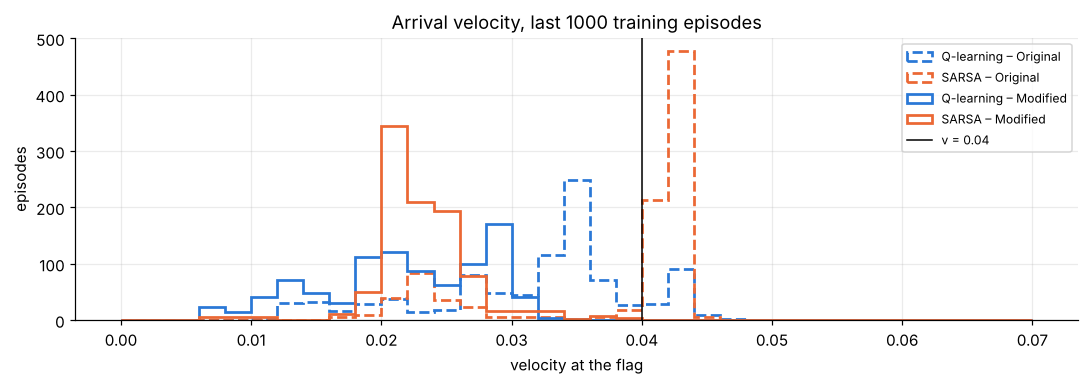

,arrivals_last1000,median_arrival_v,share_gentle_of_arrivals
run,,,
Q-learning – Original,951,0.0340,0.8612
SARSA – Original,936,0.0422,0.2564
Q-learning – Modified,930,0.0220,1.0000
SARSA – Modified,967,0.0228,1.0000


In [23]:
arr_rows = []
fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.linspace(0, 0.07, 36)
for (algo, env_name), h in HIST.items():
    v = h["arrival_v"].tail(1000).dropna()
    arr_rows.append(dict(run=f"{algo} – {env_name}", arrivals_last1000=len(v),
                         median_arrival_v=v.median(), share_gentle_of_arrivals=(v <= GENTLE_VMAX).mean()))
    ax.hist(v, bins=bins, histtype="step", lw=1.8, color=ALGO_COLOR[algo], ls=ENV_STYLE[env_name],
            label=f"{algo} – {env_name}")
ax.axvline(GENTLE_VMAX, color="k", lw=1, label="v = 0.04")
ax.set(title="Arrival velocity, last 1000 training episodes", xlabel="velocity at the flag", ylabel="episodes")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
ARR = pd.DataFrame(arr_rows).set_index("run"); display(ARR)

**Interpretation.** Arrival velocities in the modified environment are concentrated **well below 0.04** (median 0.022 for Q-learning and 0.023 for SARSA, with 100 % of arrivals gentle). In the original environment they cluster around and above the threshold (median 0.034 for Q-learning and 0.042 for SARSA, with only 86 % and 26 % gentle). The +20 bonus clearly moves the whole arrival distribution to lower speeds, not just past the threshold.

### d.8 Extra training diagnostics: episode length, TD error, switching and stuck events
These four panels go beyond the required plots and show *how* the sticky actuator changes the learning process:

* **Episode length** (moving average) is a reward-free measure of speed that can be compared across both environments;
* **mean |TD error| per step** measures how "surprised" the value function is by each transition. Extra transition noise should keep it higher;
* **action switches per episode** counts how often the agent *changes* its selected action. Only a switch can get stuck, so a smart agent under a sticky actuator might learn to switch less;
* **blocked changes per episode** (modified environment only) comes from the wrapper's private counter. It shows how often the actuator actually ignored the agent.

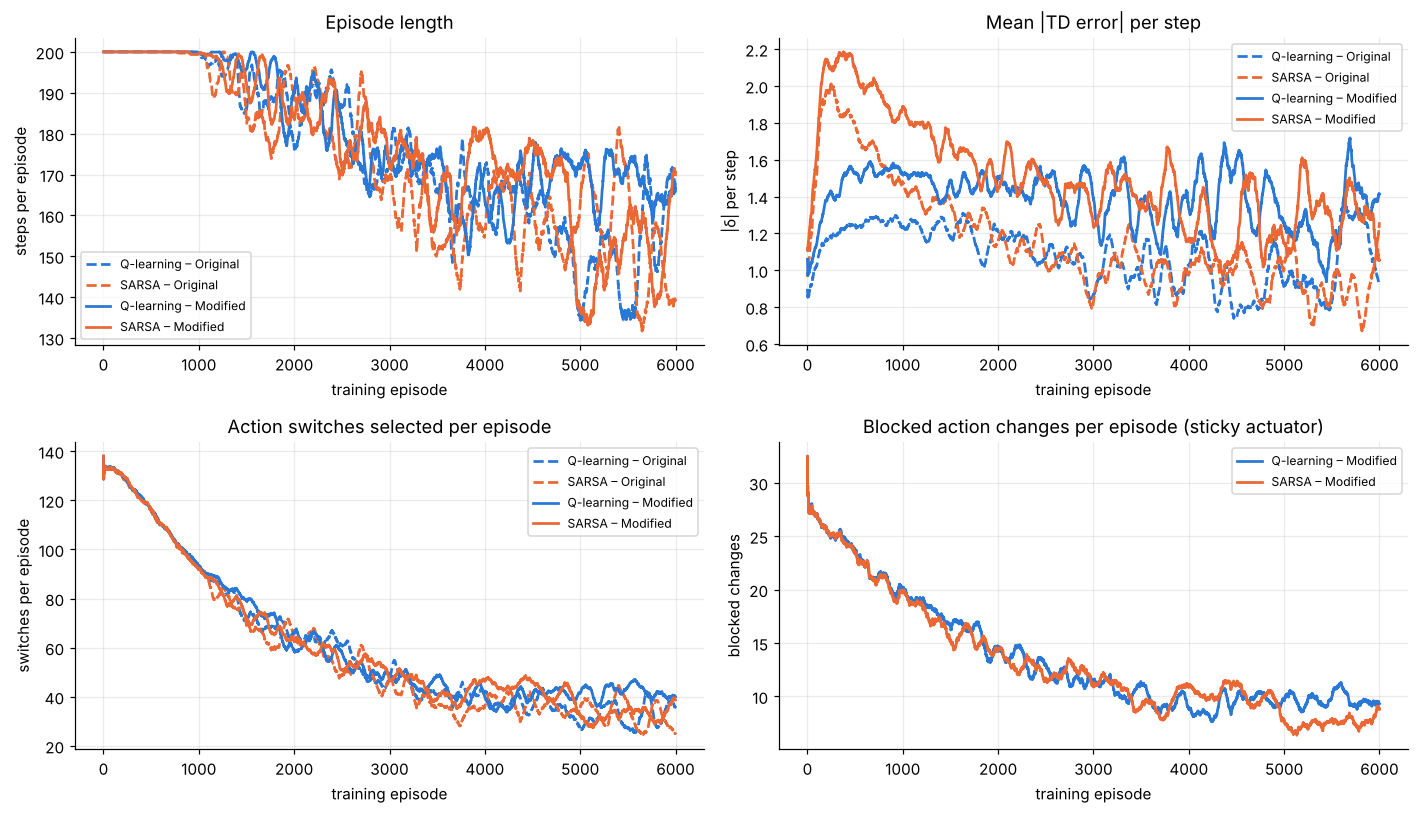

Last 1000 training episodes:


,length,td_abs,switches,switch_rate,blocked
Q-learning – Original,152.790,1.0438,32.943,0.2096,0.000
SARSA – Original,154.281,0.9338,32.787,0.2078,0.000
Q-learning – Modified,167.777,1.2847,42.083,0.2488,9.661
SARSA – Modified,151.627,1.3040,33.079,0.2133,7.581


In [24]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
plot_metric(ax[0, 0], "length", "Episode length", "steps per episode")
plot_metric(ax[0, 1], "td_abs", "Mean |TD error| per step", "|δ| per step")
plot_metric(ax[1, 0], "switches", "Action switches selected per episode", "switches per episode")
plot_metric(ax[1, 1], "stuck", "Blocked action changes per episode (sticky actuator)", "blocked changes", envs=("Modified",))
plt.tight_layout(); plt.show()

# Numerical summary of the same diagnostics over the last 1000 training episodes
diag = pd.DataFrame({f"{a} – {e}": dict(length=h["length"].tail(1000).mean(),
                                         td_abs=h["td_abs"].tail(1000).mean(),
                                         switches=h["switches"].tail(1000).mean(),
                                         switch_rate=(h["switches"] / h["length"]).tail(1000).mean(),
                                         blocked=h["stuck"].tail(1000).mean())
                     for (a, e), h in HIST.items()}).T
print("Last 1000 training episodes:"); display(diag)

**Interpretation.**

* **Episode length.** All four agents shorten their episodes from 200 to about 150–170 steps. Over the last 1 000 episodes, Q-learning-modified is the slowest (168 steps), while SARSA-modified (152) is as fast as both original agents (153–154). So the sticky actuator does not have to cost speed, but the Q-learning agent pays some.
* **TD error.** In the last 1 000 episodes the mean |δ| per step is **about 25–40 % higher in the modified environment** (1.28–1.30, against 0.93–1.04). This is the extra transition noise the agent cannot explain: the same (s, a) sometimes leads to the result of another action, and occasionally to a +20 bonus. Early in training SARSA's |δ| peaks higher than Q-learning's (up to about 2.2), because its target includes noisy exploratory actions.
* **Switching.** Every agent learns to switch far less than a random policy (from about 135 to about 33–42 switches per episode). In the modified environment **SARSA switches less than Q-learning** (0.213 vs 0.249 switches per step). SARSA keeps the same switch rate as in the original environment, while Q-learning switches *more*, because it now mixes "None" into its pushes.
* **Blocked changes.** Fewer switches mean fewer opportunities for the actuator to stick. Blocked changes fall from about 28 per episode (random play) to 9.7 for Q-learning and 7.6 for SARSA. That SARSA ends up hit by fewer stuck events is an early sign of its on-policy, noise-aware behaviour (see e.4).

### d.9 Value-function landscapes and where the two algorithms disagree
**Top row (four panels):** the learned state value V(s) = max_a Q(s,a) on the position × velocity grid for each agent. Darker cells are worse (more negative). Never-visited cells are white.

**Bottom row:** the cell-by-cell difference **V_Q-learning − V_SARSA** for each environment, on a diverging scale with a grey midpoint (blue = Q-learning more optimistic). This turns the single "average max Q" number from d.2 into a map, so it shows *where* in state space the optimism of Q-learning sits.

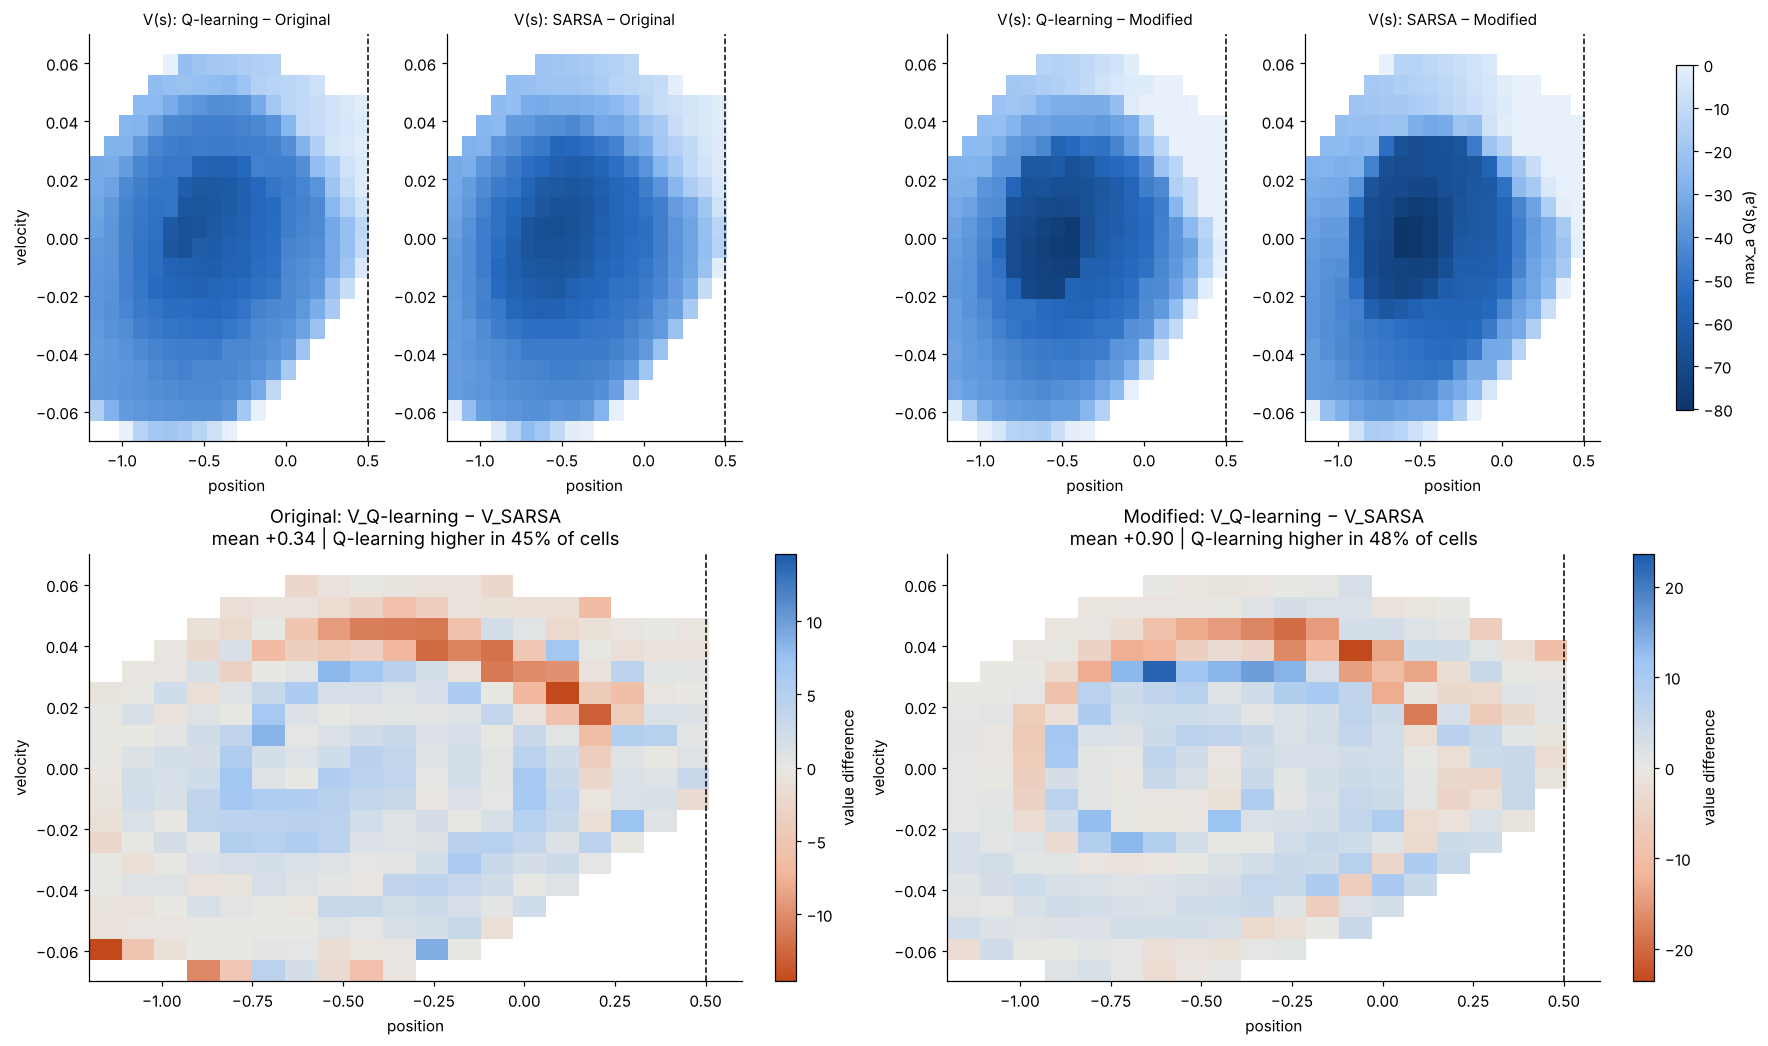

,mean_diff,mean_abs_diff,share_QL_higher,max_abs_diff
environment,,,,
Original,0.3367,2.6346,0.4500,14.5613
Modified,0.9045,4.0621,0.4775,23.5758


In [25]:
SEQ_CMAP = LinearSegmentedColormap.from_list("seq", ["#0d366b", "#256abf", "#86b6ef", "#e7f0fb"])   # dark = low V
DIV_CMAP = LinearSegmentedColormap.from_list("div", ["#c2491b", "#f2b79c", "#e8e7e3", "#9ec5f4", "#1c5cab"])

def value_grid(agent):
    """V(s) = max_a Q(s,a) per grid cell; NaN where the state was never updated."""
    v = agent.Q.max(axis=-1).astype(float)
    v[np.all(agent.Q == 0, axis=-1)] = np.nan
    return v

keys4 = [("Q-learning", "Original"), ("SARSA", "Original"), ("Q-learning", "Modified"), ("SARSA", "Modified")]
V = {k: value_grid(AGENTS[k]) for k in keys4}
vmin = np.nanmin([np.nanmin(v) for v in V.values()])

fig = plt.figure(figsize=(16, 9.4), constrained_layout=True)
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.05])
for i, k in enumerate(keys4):
    ax = fig.add_subplot(gs[0, i])
    im = ax.pcolormesh(pos_c, vel_c, V[k].T, cmap=SEQ_CMAP, vmin=vmin, vmax=0, shading="nearest")
    ax.axvline(FLAG_POS, color="k", ls="--", lw=1); ax.grid(False)
    ax.set_title(f"V(s): {k[0]} – {k[1]}", fontsize=10); ax.set_xlabel("position")
    if i == 0: ax.set_ylabel("velocity")
fig.colorbar(im, ax=fig.axes[:4], shrink=0.85, label="max_a Q(s,a)")

diff_rows = []
for j, env_name in enumerate(("Original", "Modified")):
    d = V[("Q-learning", env_name)] - V[("SARSA", env_name)]
    lim = np.nanmax(np.abs(d))
    ax = fig.add_subplot(gs[1, 2 * j: 2 * j + 2])
    im2 = ax.pcolormesh(pos_c, vel_c, d.T, cmap=DIV_CMAP, norm=TwoSlopeNorm(0, -lim, lim), shading="nearest")
    ax.axvline(FLAG_POS, color="k", ls="--", lw=1); ax.grid(False)
    ax.set(title=f"{env_name}: V_Q-learning − V_SARSA\nmean {np.nanmean(d):+.2f} | Q-learning higher in {np.nanmean(d > 0):.0%} of cells",
           xlabel="position", ylabel="velocity")
    fig.colorbar(im2, ax=ax, label="value difference")
    diff_rows.append(dict(environment=env_name, mean_diff=np.nanmean(d), mean_abs_diff=np.nanmean(np.abs(d)),
                          share_QL_higher=np.nanmean(d > 0), max_abs_diff=lim))
plt.show()
display(pd.DataFrame(diff_rows).set_index("environment"))

**Interpretation.**

* **Shape.** All four value maps have the same spiral "valley": the lowest values (about −60 to −80) sit around the start region (x ≈ −0.5, v ≈ 0), where the most swings are still needed, and values rise towards the flag. In the modified maps the valley is **deeper** (each step costs up to −1.2) and the area next to the flag is **brighter**, because the +20 bonus is close.
* **Where the algorithms disagree.** The difference maps show that the disagreement is **not uniform**. Q-learning is higher by a small amount over much of the oval, but the large differences of both signs sit in a narrow band at **v ≈ 0.03–0.05 on the final approach**. That is where a single decision decides between reaching the flag, overshooting the 0.04 limit, or falling back for another swing. Q-learning is higher in fewer than half of the cells (45–48 %), yet its mean advantage is positive because its positive differences are larger.
* **Effect of the sticky actuator.** The disagreement is larger in the modified environment on every summary: mean difference +0.90 vs +0.34, mean |difference| 4.06 vs 2.63, maximum 23.6 vs 14.6. In the modified environment it concentrates almost exactly on the 0.04 gentle-arrival line, where a single blocked command can cost the +20 bonus.

### d.10 State-visitation maps
These plot the number of Q-updates per grid cell over the whole 6 000-episode run (log scale). The maps show which parts of the state space each agent actually experienced. That tells us how reliable the policy maps and value maps are in each region, and whether the sticky actuator changes the paths the agent travels.

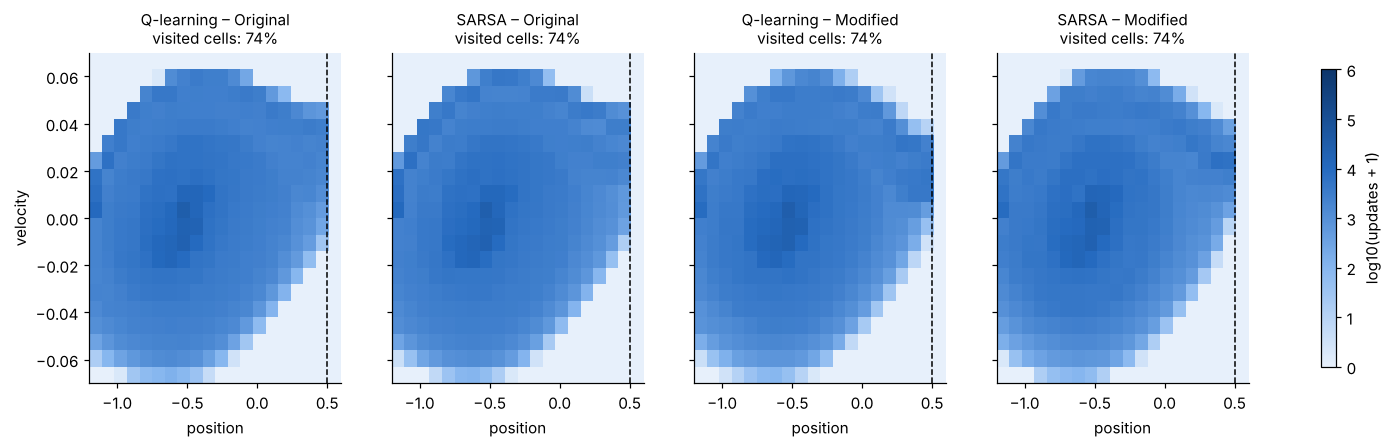

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for ax, k in zip(axes, keys4):
    n = AGENTS[k].N.sum(axis=-1).astype(float)
    im = ax.pcolormesh(pos_c, vel_c, np.log10(n + 1).T, cmap=SEQ_CMAP.reversed(), vmin=0, vmax=6, shading="nearest")
    ax.axvline(FLAG_POS, color="k", ls="--", lw=1); ax.grid(False)
    ax.set_title(f"{k[0]} – {k[1]}\nvisited cells: {(n > 0).mean():.0%}", fontsize=10); ax.set_xlabel("position")
axes[0].set_ylabel("velocity")
fig.colorbar(im, ax=axes, shrink=0.9, label="log10(updates + 1)")
plt.show()

**Interpretation.** All four agents visit the same 74 % of the grid. The unvisited corners (for example, high speed at the left wall) cannot be reached under the MountainCar physics. Visits are densest around the start region and along the energy-pumping spiral. The modified agents visit the **fast corner just before the flag** (x > 0.3, v > 0.04) less often, which fits their slower approach. Since every agent covers the same region, the differences in d.5 and d.9 come from *how* the agents value states, not from where they have been. Cells at the edge of the oval have few updates, so policy-map colours there should be read with care.

### d.11 What the greedy policies actually do: trajectories with stuck events
Each final greedy agent is run from the **same start state** (test seed 10 000). Its path is drawn in phase space over its own policy map (left), and its position is plotted against time (right). In the modified environment, a private trace marks every step where the actuator **ignored** the agent's requested change (✕). This shows directly how a stuck actuator bends the swing and what the agent does near the flag.

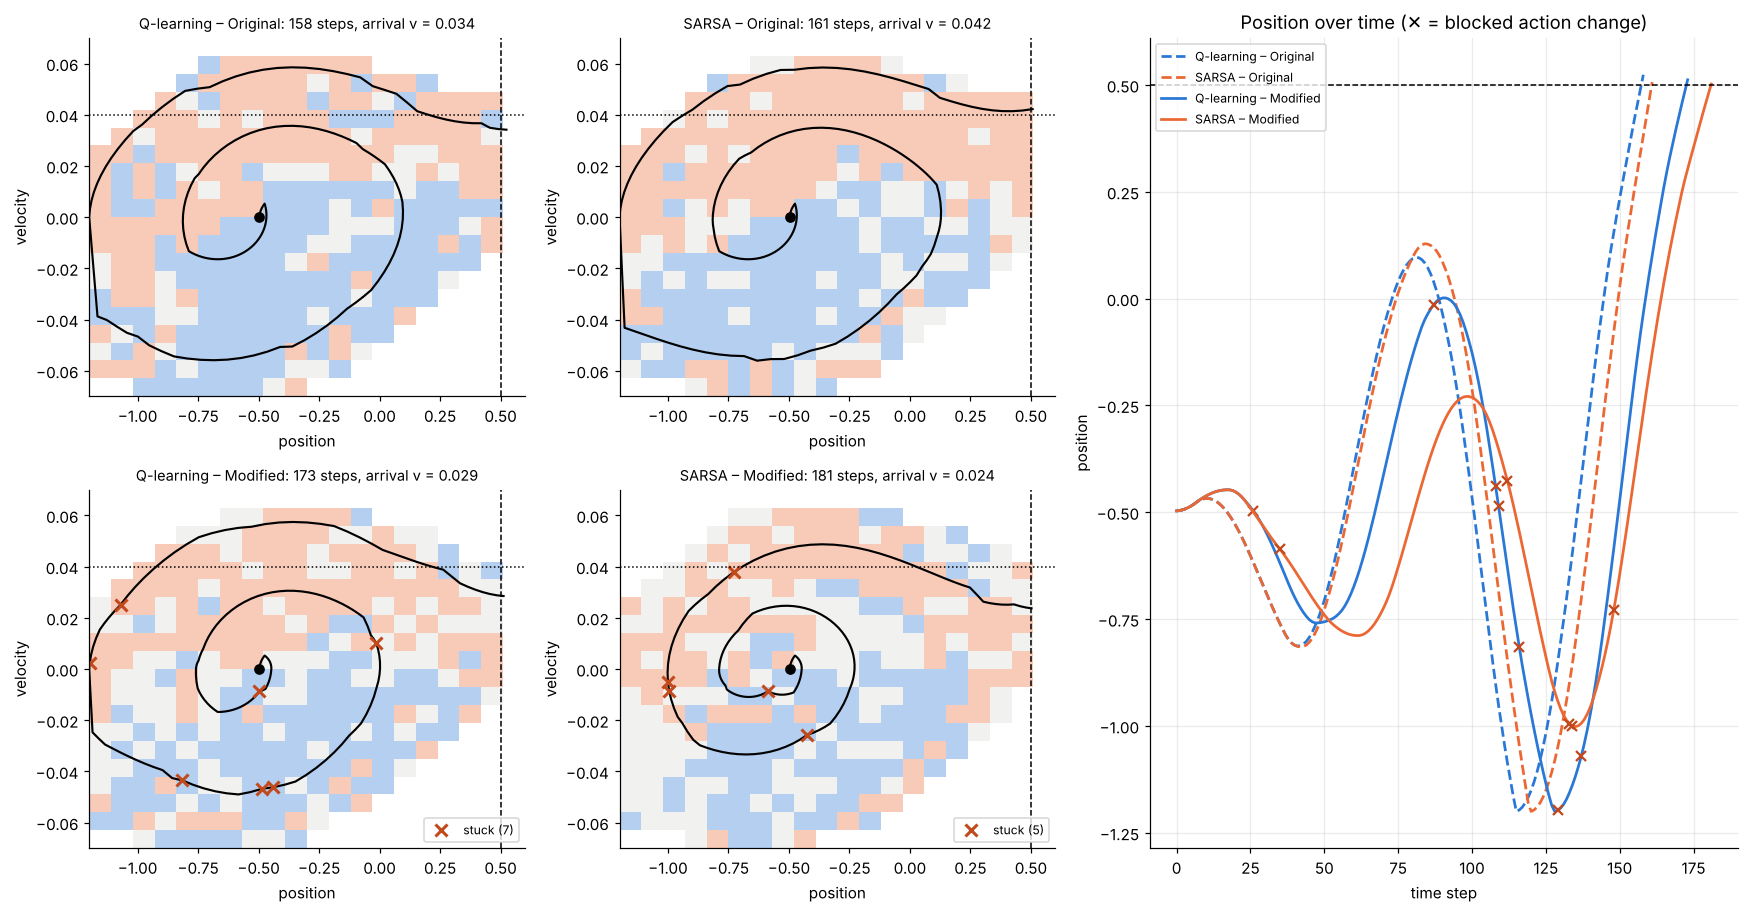

In [27]:
def greedy_rollout(agent, modified, seed):
    """Run one greedy episode from a fixed seed and return its step-by-step trace as a DataFrame."""
    env = make_env(modified, seed=seed, record_trace=True)
    state_fn = build_state_fn(agent.disc, env, getattr(agent, "oracle", False))
    obs, _ = env.reset(seed=seed); rows = [dict(t=0, pos=obs[0], vel=obs[1], a=np.nan, stuck=False)]
    while True:
        a = int(np.argmax(agent.Q[state_fn(obs)]))
        obs, r, te, tr, _ = env.step(a)
        stuck = bool(env._trace[-1]["a_exec"] != a) if modified else False
        rows.append(dict(t=len(rows), pos=obs[0], vel=obs[1], a=a, stuck=stuck))
        if te or tr:
            break
    env.close()
    return pd.DataFrame(rows)

ROLL = {k: greedy_rollout(AGENTS[k], k[1] == "Modified", CFG["test_seed_base"]) for k in keys4}
fig = plt.figure(figsize=(16, 8.4))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.35])
for i, k in enumerate(keys4):
    ax = fig.add_subplot(gs[i // 2, i % 2]); tr_ = ROLL[k]
    ax.pcolormesh(pos_c, vel_c, policy_grid(AGENTS[k]).T, cmap=POLICY_CMAP, alpha=0.35,
                  norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3), shading="nearest")
    ax.plot(tr_["pos"], tr_["vel"], color="k", lw=1.4)
    ax.plot(tr_["pos"].iloc[0], tr_["vel"].iloc[0], "o", color="k", ms=6)
    st = tr_[tr_["stuck"]]
    ax.plot(st["pos"], st["vel"], "x", color="#c2491b", ms=8, mew=2, label=f"stuck ({len(st)})")
    ax.axvline(FLAG_POS, color="k", ls="--", lw=1); ax.axhline(GENTLE_VMAX, color="k", ls=":", lw=1); ax.grid(False)
    ax.set_title(f"{k[0]} – {k[1]}: {len(tr_) - 1} steps, arrival v = {tr_['vel'].iloc[-1]:.3f}", fontsize=9.5)
    ax.set_xlabel("position"); ax.set_ylabel("velocity")
    if len(st): ax.legend(fontsize=8, loc="lower right")
ax = fig.add_subplot(gs[:, 2])
for k in keys4:
    tr_ = ROLL[k]
    ax.plot(tr_["t"], tr_["pos"], color=ALGO_COLOR[k[0]], ls=ENV_STYLE[k[1]], lw=1.8, label=f"{k[0]} – {k[1]}")
    st = tr_[tr_["stuck"]]; ax.plot(st["t"], st["pos"], "x", color="#c2491b", ms=6, mew=1.5)
ax.axhline(FLAG_POS, color="k", ls="--", lw=1)
ax.set(title="Position over time (✕ = blocked action change)", xlabel="time step", ylabel="position")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Interpretation.**

* From the same start (x ≈ −0.5, v = 0), all four policies use the classic swing: back to the left wall, then up to the flag. The **original** agents finish in 158 (Q-learning) and 161 (SARSA) steps and hit the flag at 0.034 and 0.042. The **modified** agents take longer (173 and 181 steps) but arrive more slowly (0.029 and 0.024). Both earn the bonus.
* The modified trajectories are visibly **flatter on the final approach**: the velocity curve bends down towards the 0.04 line before x = 0.5. That is the coasting / braking behaviour from the policy maps. SARSA-modified also makes a smaller first swing (peak at x ≈ −0.23) and needs a deeper extra swing to the left, which explains its longer episode.
* **Stuck events (✕)** (7 for Q-learning, 5 for SARSA) all happen **at the turning points of the swing**, where the policy switches between Left and Right, and **none happen on the final approach**. The agents have learned to hold one command steadily where it matters most. They only switch where a short delay costs little, because the car is nearly at rest at a turning point.

---
## X. Extended experiments (beyond the brief)

The required experiments use one seed and one stickiness level. That makes some conclusions fragile, as the single-seed greedy results in d.6 showed. This section adds three experiments to test the main claims of the discussion:

| Experiment | Question it answers | Discussion item |
|---|---|---|
| **X.1 Multi-seed robustness** (5 seeds × 4 agents) | Are the Q-learning vs SARSA and original vs modified differences real, or seed luck? | e.1, e.4, e.5 |
| **X.2 Stickiness sweep** (p = 0 … 0.5) | Does the Q-learning − SARSA value gap grow with actuator noise? How does performance degrade? | e.1, e.4 |
| **X.3 `a_prev`-aware oracle** | How much does the *hidden* actuator state cost? | e.2 |
| **X.4 Scorecard** | Overall comparison on several criteria at once | e.4 |

All of them reuse the same `train_agent` / `evaluate_greedy` functions and the same hyperparameters (`CFG`). Only the seed, the stick probability or the observation given to the agent changes. The oracle agent is used **for analysis only**: it breaks the "no extra observations" rule on purpose, to measure what that rule costs.

### X.1 Multi-seed robustness (5 independent seeds)
This cell trains all four configurations on seeds 42, 7, 123, 2024 and 31415. Seed 42 reuses the main runs above. Each finished agent gets the same 100-episode greedy test as d.6. The progress log is printed every 1 000 episodes to keep the report readable. About 7 minutes on a typical CPU.

In [28]:
SEED_HIST, SEED_EVAL = {}, []
if RUN_EXTENDED:
    t_start = time.time()
    for sd in EXT["seeds"]:
        for env_name, modified in (("Original", False), ("Modified", True)):
            for algo in ("Q-learning", "SARSA"):
                if sd == CFG["seed"]:                                    # reuse the main experiment
                    ag, h = AGENTS[(algo, env_name)], HIST[(algo, env_name)]
                else:
                    ag, h = train_agent(algo, modified, seed=sd, log_every=EXT["log_every"])
                SEED_HIST[(algo, env_name, sd)] = h
                ev = evaluate_greedy(ag, modified)
                last = h.tail(1000)
                SEED_EVAL.append(dict(algo=algo, env=env_name, seed=sd, **ev,
                                      train_reward_last1000=last["reward"].mean(),
                                      train_success_last1000=last["success"].mean(),
                                      train_gentle_last1000=last["gentle"].mean(),
                                      train_pushes_last1000=last["pushes"].mean()))
    SEED_EVAL = pd.DataFrame(SEED_EVAL)
    print(f"Multi-seed study finished in {time.time() - t_start:.0f} s")

[Q-learning | Original | seed=7] ep     1 | eps 1.000 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  135.0 | len  200.0 | avg maxQ    -0.01


[Q-learning | Original | seed=7] ep  1000 | eps 0.279 | R  -200.00 | MA100 R  -198.24 | succ 0.08 | gentle 0.08 | push  144.3 | len  198.2 | avg maxQ    -7.75


[Q-learning | Original | seed=7] ep  2000 | eps 0.078 | R  -200.00 | MA100 R  -182.30 | succ 0.52 | gentle 0.52 | push  138.7 | len  182.3 | avg maxQ   -15.34


[Q-learning | Original | seed=7] ep  3000 | eps 0.022 | R  -170.00 | MA100 R  -165.96 | succ 0.73 | gentle 0.68 | push  133.0 | len  166.0 | avg maxQ   -20.78


[Q-learning | Original | seed=7] ep  4000 | eps 0.010 | R  -108.00 | MA100 R  -132.75 | succ 1.00 | gentle 0.94 | push  118.0 | len  132.8 | avg maxQ   -23.41


[Q-learning | Original | seed=7] ep  5000 | eps 0.010 | R  -186.00 | MA100 R  -170.54 | succ 0.97 | gentle 0.01 | push  146.4 | len  170.5 | avg maxQ   -25.34


... (103 outputs left out)

[SARSA      | Modified | seed=31415] ep  4000 | eps 0.010 | R  -121.60 | MA100 R  -141.31 | succ 1.00 | gentle 1.00 | push  104.0 | len  140.5 | avg maxQ   -23.77


[SARSA      | Modified | seed=31415] ep  5000 | eps 0.010 | R  -118.80 | MA100 R  -140.99 | succ 0.99 | gentle 0.99 | push  100.1 | len  140.8 | avg maxQ   -24.43


[SARSA      | Modified | seed=31415] ep  6000 | eps 0.010 | R  -153.60 | MA100 R  -177.90 | succ 0.87 | gentle 0.87 | push  121.5 | len  170.8 | avg maxQ   -26.24
[SARSA      | Modified | seed=31415] finished 6000 episodes in 25.8 s


Multi-seed study finished in 407 s


#### X.1.1 Learning curves: mean across seeds with 95 % confidence bands
The line is the mean over the five seeds of each 100-episode moving average. The band is a 95 % t-interval across seeds. The third panel repeats the d.2 value gap (Q-learning − SARSA average max Q) for every seed, so the "larger gap under sticky actuators" claim can be checked against seed-to-seed variation.

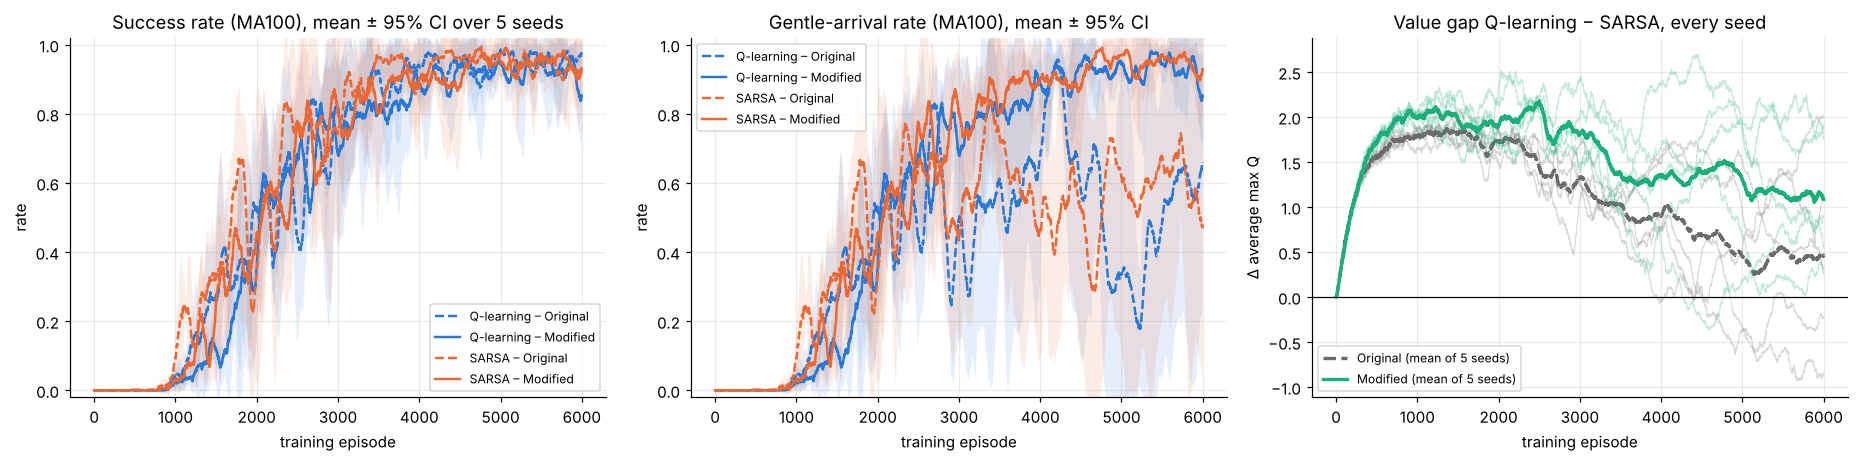

In [29]:
def seed_band(column, algo, env_name, transform=moving_average):
    """Mean and 95% t-interval across seeds of a per-episode metric (after the moving average)."""
    arr = np.array([transform(SEED_HIST[(algo, env_name, sd)][column].values) for sd in EXT["seeds"]])
    m, se = arr.mean(0), arr.std(0, ddof=1) / np.sqrt(len(arr))
    return m, stats.t.ppf(0.975, len(arr) - 1) * se

if RUN_EXTENDED:
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
    x = np.arange(CFG["n_episodes"])
    for col, a_, title in (("success", ax[0], "Success rate (MA100), mean ± 95% CI over 5 seeds"),
                           ("gentle", ax[1], "Gentle-arrival rate (MA100), mean ± 95% CI")):
        for algo in ("Q-learning", "SARSA"):
            for env_name in ("Original", "Modified"):
                m, ci = seed_band(col, algo, env_name)
                a_.plot(x, m, color=ALGO_COLOR[algo], ls=ENV_STYLE[env_name], lw=1.6, label=f"{algo} – {env_name}")
                a_.fill_between(x, m - ci, m + ci, color=ALGO_COLOR[algo], alpha=0.12, lw=0)
        a_.set(title=title, xlabel="training episode", ylabel="rate", ylim=(-0.02, 1.02)); a_.legend(fontsize=8)

    GAP = {}
    for env_name, c in (("Original", "#6b6b6b"), ("Modified", "#1baf7a")):
        gaps = np.array([SEED_HIST[("Q-learning", env_name, sd)]["avg_max_q"].values -
                         SEED_HIST[("SARSA", env_name, sd)]["avg_max_q"].values for sd in EXT["seeds"]])
        GAP[env_name] = gaps
        for g in gaps:
            ax[2].plot(x, g, color=c, alpha=0.25, lw=0.8)
        ax[2].plot(x, gaps.mean(0), color=c, lw=2.2, ls=ENV_STYLE[env_name], label=f"{env_name} (mean of 5 seeds)")
    ax[2].axhline(0, color="k", lw=0.8)
    ax[2].set(title="Value gap Q-learning − SARSA, every seed", xlabel="training episode", ylabel="Δ average max Q")
    ax[2].legend(fontsize=8); plt.tight_layout(); plt.show()

#### X.1.2 Greedy test results across seeds, and significance tests
The left plot shows each seed's greedy success rate and gentle-arrival rate as a dot, with the mean as a bar. The table gives mean ± standard deviation over the seeds. Two **paired t-tests** (paired by seed, n = 5) then check the two central comparisons:

1. Q-learning vs SARSA in the modified environment;
2. whether the Q-learning − SARSA value gap (mean |gap| over training) is larger in the modified environment than in the original.

With only five seeds the tests have low power. They are reported as supporting evidence, not proof.

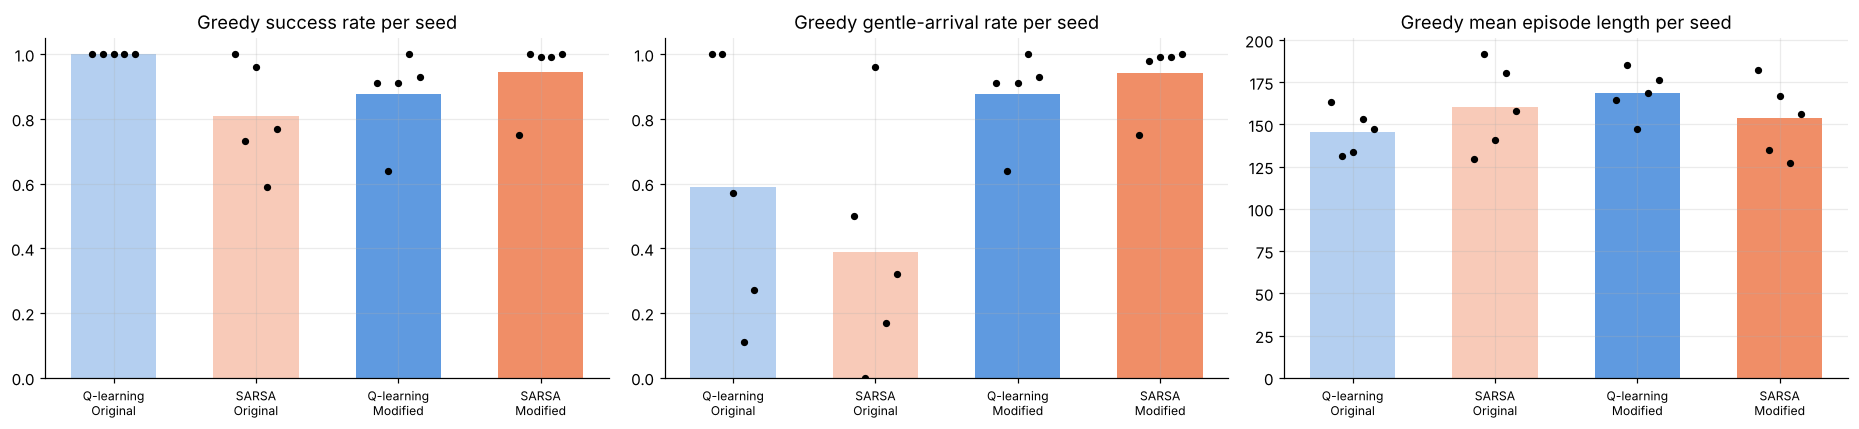

Mean ± std over 5 seeds (greedy test = first six columns, last-1000 training episodes = last three):


,,mean_reward,success_rate,gentle_arrival_rate,mean_episode_length,mean_pushes,mean_arrival_velocity,train_reward_last1000,train_success_last1000,train_pushes_last1000
algo,env,,,,,,,,,
Q-learning,Original,-145.76 ± 13.357,1.0 ± 0.0,0.59 ± 0.409,145.76 ± 13.357,124.32 ± 13.463,0.038 ± 0.003,-155.22 ± 4.11,0.951 ± 0.013,130.439 ± 2.031
SARSA,Original,-160.198 ± 26.035,0.81 ± 0.17,0.39 ± 0.368,160.198 ± 26.035,136.774 ± 21.064,0.034 ± 0.005,-157.087 ± 3.381,0.937 ± 0.014,132.221 ± 3.094
Q-learning,Modified,-174.862 ± 18.394,0.878 ± 0.138,0.878 ± 0.138,168.502 ± 14.262,118.802 ± 14.337,0.025 ± 0.003,-163.279 ± 6.004,0.925 ± 0.032,109.861 ± 1.584
SARSA,Modified,-155.589 ± 24.887,0.946 ± 0.11,0.942 ± 0.108,153.552 ± 22.743,104.384 ± 4.07,0.025 ± 0.003,-157.19 ± 11.314,0.948 ± 0.029,107.253 ± 7.56


Per-seed mean |gap| – Original: [1.16 1.36 1.45 1.06 1.  ] | Modified: [1.76 1.86 1.61 1.36 1.28]


,mean_difference,t,p_value
comparison,,,
Modified env: Q-learning vs SARSA – success_rate,-0.0680,-0.8028,0.4671
Modified env: Q-learning vs SARSA – mean_reward,-19.2736,-1.1451,0.3160
Modified env: Q-learning vs SARSA – train_reward_last1000,-6.0885,-0.8634,0.4366
Modified env: Q-learning vs SARSA – train_success_last1000,-0.0236,-0.9774,0.3837
Mean |Q-learning − SARSA value gap|: Modified vs Original,0.3685,4.6961,0.0093


In [30]:
if RUN_EXTENDED:
    order = [("Q-learning", "Original"), ("SARSA", "Original"), ("Q-learning", "Modified"), ("SARSA", "Modified")]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    for a_, col, title in ((ax[0], "success_rate", "Greedy success rate per seed"),
                           (ax[1], "gentle_arrival_rate", "Greedy gentle-arrival rate per seed"),
                           (ax[2], "mean_episode_length", "Greedy mean episode length per seed")):
        for i, (algo, env_name) in enumerate(order):
            vals = SEED_EVAL.query("algo == @algo and env == @env_name")[col].values
            a_.bar(i, vals.mean(), color=ALGO_COLOR[algo], alpha=0.35 if env_name == "Original" else 0.75, width=0.6)
            a_.scatter(np.full(len(vals), i) + np.linspace(-0.15, 0.15, len(vals)), vals, color="k", s=14, zorder=3)
        a_.set_xticks(range(4)); a_.set_xticklabels([f"{a}\n{e}" for a, e in order], fontsize=8); a_.set_title(title)
    ax[0].set_ylim(0, 1.05); ax[1].set_ylim(0, 1.05)
    plt.tight_layout(); plt.show()

    cols = ["mean_reward", "success_rate", "gentle_arrival_rate", "mean_episode_length", "mean_pushes",
            "mean_arrival_velocity", "train_reward_last1000", "train_success_last1000", "train_pushes_last1000"]
    g = SEED_EVAL.groupby(["algo", "env"])[cols]
    SEED_SUMMARY = g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)
    print("Mean ± std over 5 seeds (greedy test = first six columns, last-1000 training episodes = last three):")
    display(SEED_SUMMARY.loc[[(a, e) for a, e in order]])

    # Paired t-tests (paired by seed)
    piv = lambda col, env_name: SEED_EVAL.query("env == @env_name").pivot(index="seed", columns="algo", values=col)
    tests = []
    for col in ("success_rate", "mean_reward", "train_reward_last1000", "train_success_last1000"):
        p_ = piv(col, "Modified"); t_, pv = stats.ttest_rel(p_["Q-learning"], p_["SARSA"])
        tests.append(dict(comparison=f"Modified env: Q-learning vs SARSA – {col}",
                          mean_difference=(p_["Q-learning"] - p_["SARSA"]).mean(), t=t_, p_value=pv))
    gap_o, gap_m = np.abs(GAP["Original"]).mean(1), np.abs(GAP["Modified"]).mean(1)
    t_, pv = stats.ttest_rel(gap_m, gap_o)
    tests.append(dict(comparison="Mean |Q-learning − SARSA value gap|: Modified vs Original",
                      mean_difference=(gap_m - gap_o).mean(), t=t_, p_value=pv))
    print("Per-seed mean |gap| – Original:", gap_o.round(2), "| Modified:", gap_m.round(2))
    TESTS = pd.DataFrame(tests).set_index("comparison"); display(TESTS)

**Interpretation.**

* **Single-seed results are fragile.** In the main run (seed 42), SARSA-modified had the lowest greedy success (0.75). Across five seeds, seed 42 turns out to be **SARSA's worst seed**: the others reach 0.99–1.00, giving a mean of **0.946 ± 0.11**, against **0.878 ± 0.14** for Q-learning-modified. Its training success and pushes are also on par with or better than Q-learning's. So the main-run ranking in d.6 was seed luck.
* **Gentle arrival is learned only in the modified environment.** The 5-seed gentle-arrival rate is 0.88–0.94 in the modified environment against 0.39–0.59 in the original. In the original the per-seed values scatter from 0 to 1 (std about 0.4), so gentleness there is a side effect of each seed's policy and not something the agents learn. In the modified environment it is reliable: every agent's gentle rate equals its success rate.
* **The larger value gap under sticky actuators is robust.** Mean |Q-learning − SARSA gap| is larger in the modified environment **for all five seeds** (1.28–1.86 against 1.00–1.45). A paired t-test gives a mean increase of +0.37 (t = 4.70, **p = 0.009**). The mean-gap curves separate after about episode 2 500. The original gap shrinks to about 0.5 by the end, and the modified gap stays at about 1.1.
* **Q-learning vs SARSA in the modified environment is *not* statistically significant.** SARSA is ahead on the mean of every metric (greedy success +0.07, greedy reward +19, training reward +6), but all p-values are 0.32–0.47. Five seeds can show a consistent trend, but not a decisive one.

### X.2 Stickiness sweep: how much actuator noise can each algorithm tolerate?
Both algorithms are retrained on the modified environment with stick probability p ∈ {0, 0.1, 0.2, 0.35, 0.5}, keeping the energy penalty and gentle bonus and all hyperparameters unchanged (main seed 42; p = 0.2 reuses the main runs). Note that p = 0 is **not** the original environment: it isolates the effect of the reward shaping from the effect of the sticky actuator. Six panels compare the last-1 000-episode training metrics, the greedy test results and the value gap as functions of p.

[Q-learning | Modified | p=0.0] ep     1 | eps 1.000 | R  -229.00 | MA100 R  -229.00 | succ 0.00 | gentle 0.00 | push  145.0 | len  200.0 | avg maxQ    -0.01


[Q-learning | Modified | p=0.0] ep  1000 | eps 0.279 | R  -231.40 | MA100 R  -226.36 | succ 0.03 | gentle 0.03 | push  138.9 | len  199.2 | avg maxQ    -8.45


[Q-learning | Modified | p=0.0] ep  2000 | eps 0.078 | R  -187.80 | MA100 R  -217.04 | succ 0.28 | gentle 0.28 | push  137.6 | len  194.5 | avg maxQ   -16.10


[Q-learning | Modified | p=0.0] ep  3000 | eps 0.022 | R  -231.00 | MA100 R  -173.21 | succ 0.90 | gentle 0.90 | push  124.8 | len  166.2 | avg maxQ   -19.72


[Q-learning | Modified | p=0.0] ep  4000 | eps 0.010 | R  -145.80 | MA100 R  -184.70 | succ 0.74 | gentle 0.74 | push  116.6 | len  176.0 | avg maxQ   -22.48


[Q-learning | Modified | p=0.0] ep  5000 | eps 0.010 | R  -225.80 | MA100 R  -190.01 | succ 0.77 | gentle 0.77 | push  123.4 | len  180.7 | avg maxQ   -25.22


... (46 outputs left out)

[SARSA      | Modified | p=0.5] ep  3000 | eps 0.022 | R  -187.00 | MA100 R  -184.84 | succ 0.89 | gentle 0.89 | push  126.6 | len  176.9 | avg maxQ   -22.38


[SARSA      | Modified | p=0.5] ep  4000 | eps 0.010 | R  -113.40 | MA100 R  -169.41 | succ 0.84 | gentle 0.84 | push  107.3 | len  164.7 | avg maxQ   -24.80


[SARSA      | Modified | p=0.5] ep  5000 | eps 0.010 | R  -224.20 | MA100 R  -154.78 | succ 0.91 | gentle 0.91 | push  107.3 | len  151.3 | avg maxQ   -26.32


[SARSA      | Modified | p=0.5] ep  6000 | eps 0.010 | R  -170.00 | MA100 R  -159.39 | succ 0.88 | gentle 0.88 | push  110.6 | len  154.9 | avg maxQ   -27.32
[SARSA      | Modified | p=0.5] finished 6000 episodes in 26.4 s


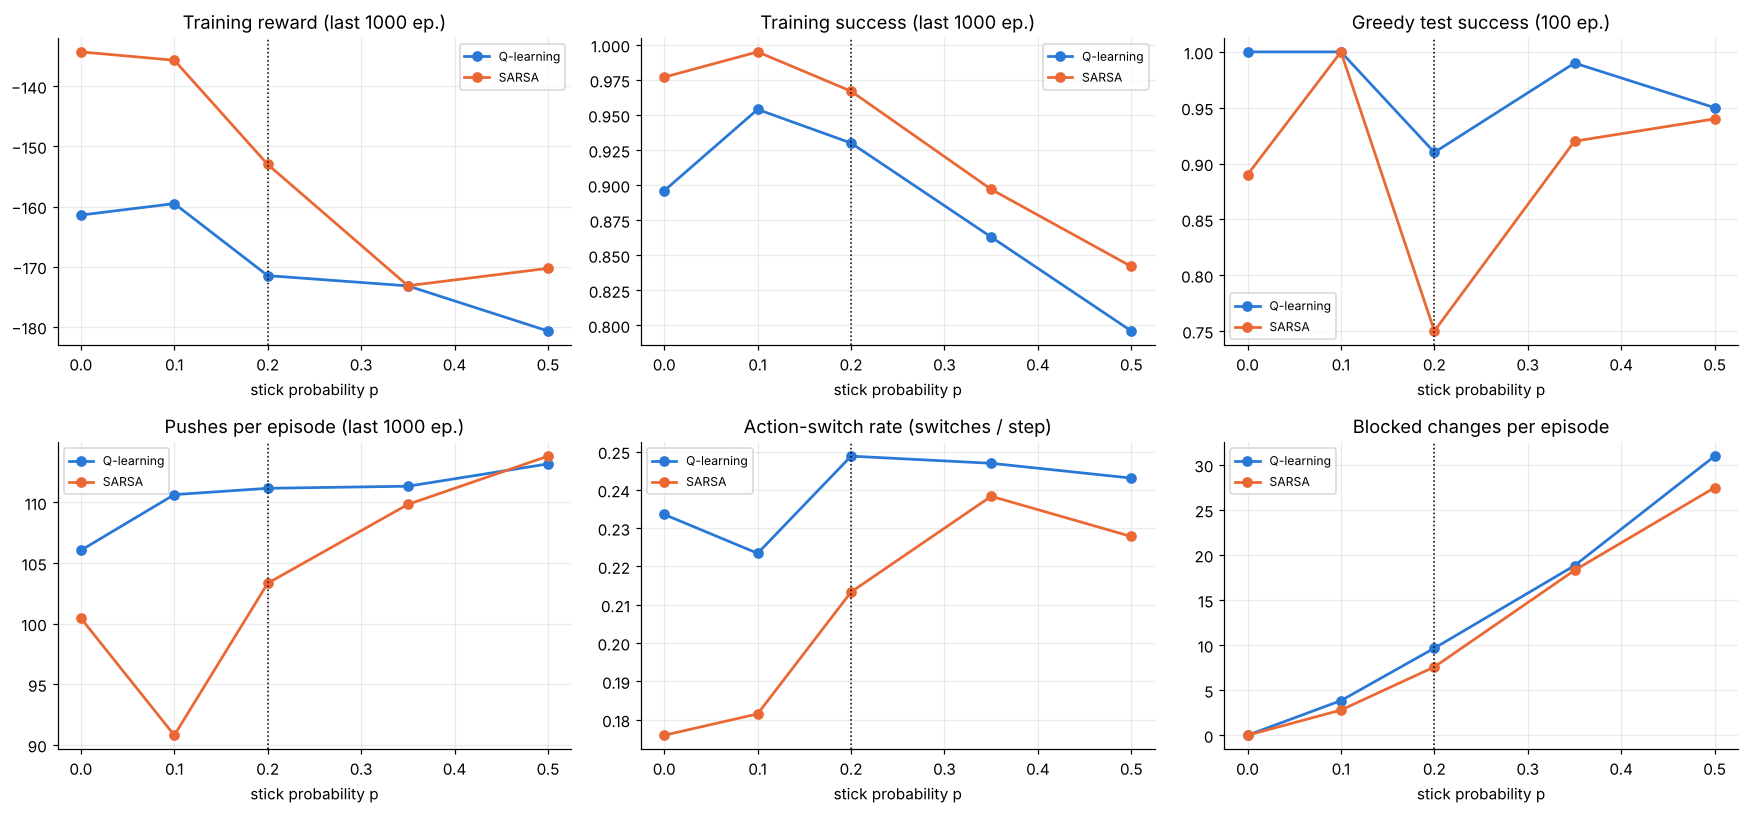

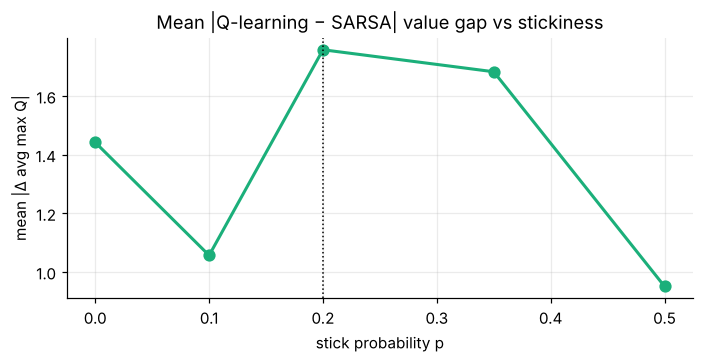

train_reward  train_success  train_pushes  switch_rate  \
p    algo                                                                 
0.00 Q-learning     -161.4204          0.896       106.052       0.2336   
     SARSA          -134.3016          0.977       100.453       0.1759   
0.10 Q-learning     -159.5158          0.954       110.649       0.2234   
     SARSA          -135.6914          0.995        90.792       0.1815   
0.20 Q-learning     -171.4908          0.930       111.169       0.2488   
     SARSA          -153.0144          0.967       103.337       0.2133   
0.35 Q-learning     -173.1900          0.863       111.340       0.2469   
     SARSA          -173.1678          0.897       109.839       0.2383   
0.50 Q-learning     -180.6940          0.796       113.185       0.2431   
     SARSA          -170.2746          0.842       113.823       0.2278   

                 blocked_per_ep  greedy_success  greedy_gentle  greedy_reward  \
p    algo                                                                       
0.00 Q-learning           0.000            1.00           1.00       -149.100   
     SARSA                0.000            0.89           0.89       -145.558   
0.10 Q-learning           3.843            1.00           1.00       -147.504   
     SARSA                2.798            1.00           1.00       -131.312   
0.20 Q-learning           9.661            0.91           0.91       -168.838   
     SARSA                7.581            0.75           0.75       -188.664   
0.35 Q-learning          18.814            0.99           0.99       -162.678   
     SARSA               18.290            0.92           0.92       -186.736   
0.50 Q-learning          30.955            0.95           0.95       -177.422   
     SARSA               27.464            0.94           0.94       -154.804   

                 mean_abs_value_gap  
p    algo                            
0.00 Q-learning              1.4418  
     SARSA                   1.4418  
0.10 Q-learning              1.0565  
     SARSA                   1.0565  
0.20 Q-learning              1.7578  
     SARSA                   1.7578  
0.35 Q-learning              1.6828  
     SARSA                   1.6828  
0.50 Q-learning              0.9507  
     SARSA                   0.9507

In [31]:
SWEEP = []
if RUN_EXTENDED:
    for p in EXT["sweep_probs"]:
        gaps = {}
        for algo in ("Q-learning", "SARSA"):
            if np.isclose(p, STICK_PROB):
                ag, h = AGENTS[(algo, "Modified")], HIST[(algo, "Modified")]
            else:
                ag, h = train_agent(algo, True, stick_prob=p, log_every=EXT["log_every"])
            ev = evaluate_greedy(ag, True, stick_prob=p)
            last = h.tail(1000); gaps[algo] = h["avg_max_q"].values
            SWEEP.append(dict(p=p, algo=algo, train_reward=last["reward"].mean(), train_success=last["success"].mean(),
                              train_pushes=last["pushes"].mean(), switch_rate=(last["switches"] / last["length"]).mean(),
                              blocked_per_ep=last["stuck"].mean(), greedy_success=ev["success_rate"],
                              greedy_gentle=ev["gentle_arrival_rate"], greedy_reward=ev["mean_reward"]))
        gap = np.abs(gaps["Q-learning"] - gaps["SARSA"]).mean()
        for row in SWEEP[-2:]:
            row["mean_abs_value_gap"] = gap
    SWEEP = pd.DataFrame(SWEEP)

    fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
    panels = [("train_reward", "Training reward (last 1000 ep.)"), ("train_success", "Training success (last 1000 ep.)"),
              ("greedy_success", "Greedy test success (100 ep.)"), ("train_pushes", "Pushes per episode (last 1000 ep.)"),
              ("switch_rate", "Action-switch rate (switches / step)"), ("blocked_per_ep", "Blocked changes per episode")]
    for a_, (col, title) in zip(ax.flat, panels):
        for algo in ("Q-learning", "SARSA"):
            d = SWEEP[SWEEP["algo"] == algo]
            a_.plot(d["p"], d[col], "o-", color=ALGO_COLOR[algo], lw=1.8, ms=6, label=algo)
        a_.axvline(STICK_PROB, color="k", ls=":", lw=1)
        a_.set(title=title, xlabel="stick probability p"); a_.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    g_ = SWEEP.drop_duplicates("p")
    ax.plot(g_["p"], g_["mean_abs_value_gap"], "o-", color="#1baf7a", lw=2, ms=7)
    ax.axvline(STICK_PROB, color="k", ls=":", lw=1)
    ax.set(title="Mean |Q-learning − SARSA| value gap vs stickiness", xlabel="stick probability p", ylabel="mean |Δ avg max Q|")
    plt.tight_layout(); plt.show()
    display(SWEEP.set_index(["p", "algo"]))

**Interpretation.**

* **The noise is real and grows linearly.** Blocked changes per episode rise roughly in proportion to p (0 → 3–4 → 8–10 → 18–19 → 27–31), and training performance degrades steadily. Q-learning's training success falls from 0.95 (p = 0.1) to 0.80 (p = 0.5), SARSA's from 0.995 to 0.84, and the training reward drops by about 20–35 points.
* **SARSA learns better online at *every* stickiness level.** Its last-1 000-episode training success and reward are higher than or equal to Q-learning's at all five values of p, and its **action-switch rate is lower at every p** (0.18–0.23 vs 0.22–0.25). This fits the on-policy picture: SARSA's values include the cost of switching under a sticky actuator, so it learns to switch less.
* **Greedy test results are noisy** (one seed, 100 episodes): Q-learning's greedy policy is ahead at most values of p, but the ranking flips from one p to the next. That matches the non-significant multi-seed result in X.1.
* **Value gap vs p.** The single-seed gap is **not monotonic** (1.44, 1.06, 1.76, 1.68, 0.95). Two things can be read from it. First, at p = 0 (reward shaping only) the gap is already 1.44, above the original environment's 1.16 for the same seed. So part of the larger gap in X.1 comes from the energy penalty and bonus, not only from stickiness. Second, at p = 0.5 the gap falls again, because with heavy stickiness both agents' values sink together and the difference between them narrows. A firmer curve would need several seeds per value of p (see e.5).

### X.3 Diagnostic oracle: what if the agent could see `a_prev`?
The modified environment is non-Markovian **only** because `a_prev` is hidden (e.2). To measure that cost directly, Q-learning and SARSA are trained once more on the modified environment with the state **(position bin, velocity bin, a_prev)**, a 20 × 20 × 3 × 3 Q-table, using the same seed and hyperparameters. This restores the Markov property. The comparison with the blind agents shows how much performance is lost to the hidden variable.

The last figure shows the oracle Q-learning policy **separately for each actuator state** a_prev ∈ {Left, None, Right}. Where the three maps differ, the best decision really does depend on information the graded agents cannot see.

[Q-learning | Modified | oracle] ep     1 | eps 1.000 | R  -229.00 | MA100 R  -229.00 | succ 0.00 | gentle 0.00 | push  145.0 | len  200.0 | avg maxQ    -0.00


[Q-learning | Modified | oracle] ep  1000 | eps 0.279 | R  -226.40 | MA100 R  -226.99 | succ 0.00 | gentle 0.00 | push  134.9 | len  200.0 | avg maxQ    -4.05


[Q-learning | Modified | oracle] ep  2000 | eps 0.078 | R  -228.20 | MA100 R  -227.35 | succ 0.00 | gentle 0.00 | push  136.7 | len  200.0 | avg maxQ    -7.68


[Q-learning | Modified | oracle] ep  3000 | eps 0.022 | R  -227.20 | MA100 R  -226.61 | succ 0.03 | gentle 0.03 | push  139.9 | len  199.2 | avg maxQ   -10.93


[Q-learning | Modified | oracle] ep  4000 | eps 0.010 | R  -229.20 | MA100 R  -225.93 | succ 0.05 | gentle 0.05 | push  139.4 | len  199.0 | avg maxQ   -14.10


[Q-learning | Modified | oracle] ep  5000 | eps 0.010 | R  -228.00 | MA100 R  -225.61 | succ 0.06 | gentle 0.06 | push  139.7 | len  198.9 | avg maxQ   -16.75


... (3 outputs left out)

[SARSA      | Modified | oracle] ep  3000 | eps 0.022 | R  -224.40 | MA100 R  -226.91 | succ 0.00 | gentle 0.00 | push  134.6 | len  200.0 | avg maxQ   -11.56


[SARSA      | Modified | oracle] ep  4000 | eps 0.010 | R  -225.80 | MA100 R  -226.61 | succ 0.03 | gentle 0.03 | push  140.3 | len  199.2 | avg maxQ   -14.51


[SARSA      | Modified | oracle] ep  5000 | eps 0.010 | R  -225.80 | MA100 R  -223.36 | succ 0.09 | gentle 0.09 | push  138.6 | len  197.4 | avg maxQ   -17.14


[SARSA      | Modified | oracle] ep  6000 | eps 0.010 | R  -168.60 | MA100 R  -210.67 | succ 0.36 | gentle 0.36 | push  134.5 | len  190.8 | avg maxQ   -19.39
[SARSA      | Modified | oracle] finished 6000 episodes in 28.6 s


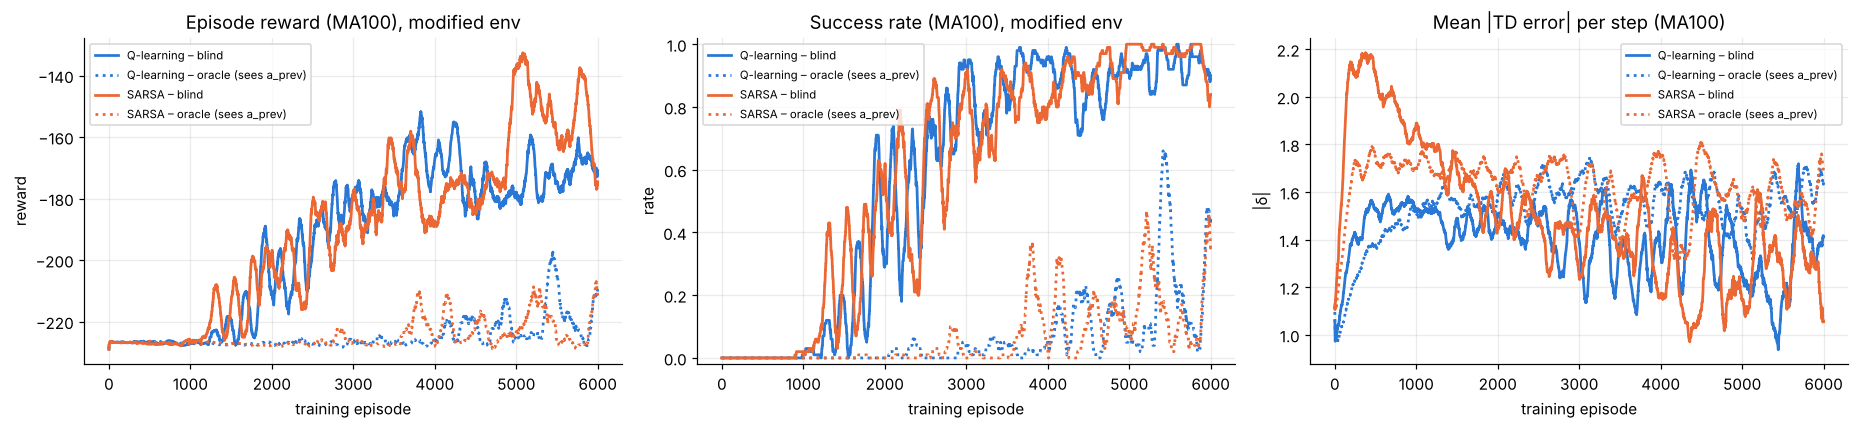

,mean_reward,std_reward,success_rate,gentle_arrival_rate,mean_episode_length,mean_pushes,mean_arrival_velocity,train_reward_last1000,train_success_last1000,td_abs_last1000
agent,,,,,,,,,,
Q-learning – blind,-168.838,30.1185,0.91,0.91,164.56,110.39,0.0262,-171.4908,0.930,1.2847
Q-learning – oracle,-225.386,13.4814,0.05,0.05,198.13,141.28,0.0185,-218.2680,0.223,1.5533
SARSA – blind,-188.664,21.5302,0.75,0.75,182.48,105.92,0.0239,-153.0144,0.967,1.3040
SARSA – oracle,-207.510,25.3127,0.37,0.37,189.15,128.80,0.0291,-220.0294,0.189,1.5732


Cells visited under all three a_prev values: 272 | greedy action identical for all three a_prev: 22%


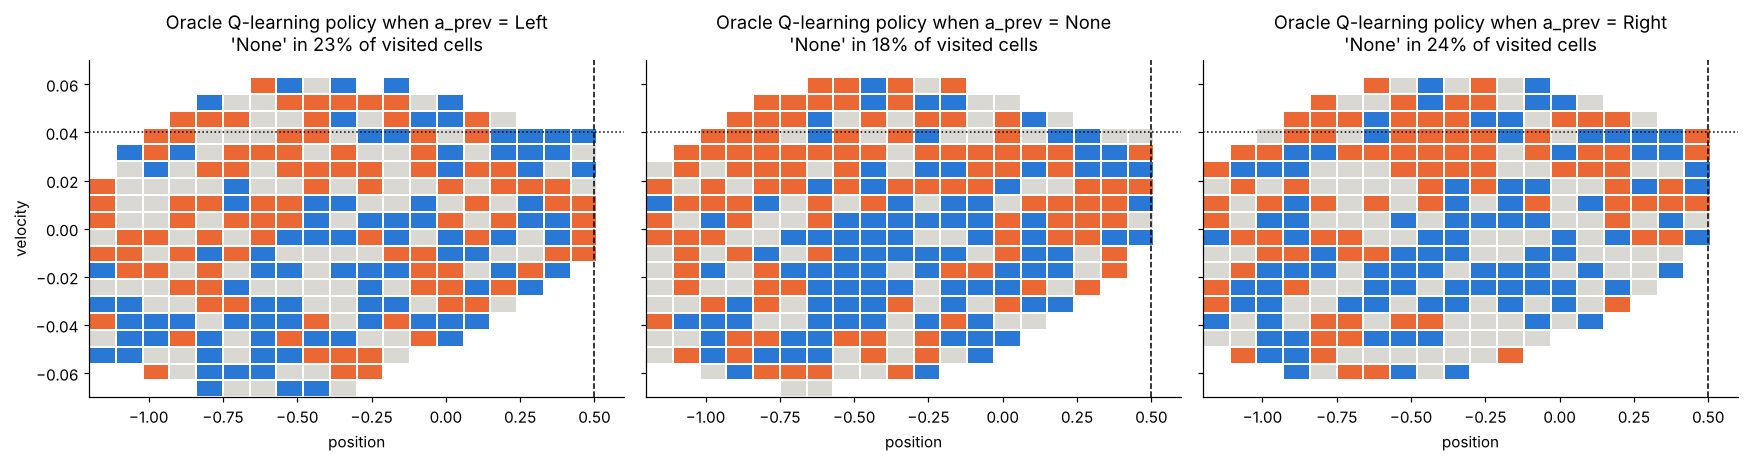

In [32]:
ORACLE = {}
if RUN_EXTENDED:
    for algo in ("Q-learning", "SARSA"):
        ORACLE[algo] = train_agent(algo, True, oracle=True, log_every=EXT["log_every"])

    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    for algo in ("Q-learning", "SARSA"):
        for lab, h, ls in (("blind", HIST[(algo, "Modified")], "-"), ("oracle (sees a_prev)", ORACLE[algo][1], ":")):
            ax[0].plot(moving_average(h["reward"]), color=ALGO_COLOR[algo], ls=ls, lw=1.8, label=f"{algo} – {lab}")
            ax[1].plot(moving_average(h["success"]), color=ALGO_COLOR[algo], ls=ls, lw=1.8, label=f"{algo} – {lab}")
            ax[2].plot(moving_average(h["td_abs"]), color=ALGO_COLOR[algo], ls=ls, lw=1.8, label=f"{algo} – {lab}")
    ax[0].set(title="Episode reward (MA100), modified env", xlabel="training episode", ylabel="reward")
    ax[1].set(title="Success rate (MA100), modified env", xlabel="training episode", ylabel="rate", ylim=(-0.02, 1.02))
    ax[2].set(title="Mean |TD error| per step (MA100)", xlabel="training episode", ylabel="|δ|")
    for a_ in ax: a_.legend(fontsize=7.5)
    plt.tight_layout(); plt.show()

    rows = []
    for algo in ("Q-learning", "SARSA"):
        for lab, ag, h in (("blind", AGENTS[(algo, "Modified")], HIST[(algo, "Modified")]),
                           ("oracle", ORACLE[algo][0], ORACLE[algo][1])):
            rows.append(dict(agent=f"{algo} – {lab}", **evaluate_greedy(ag, True),
                             train_reward_last1000=h["reward"].tail(1000).mean(),
                             train_success_last1000=h["success"].tail(1000).mean(),
                             td_abs_last1000=h["td_abs"].tail(1000).mean()))
    ORACLE_TABLE = pd.DataFrame(rows).set_index("agent"); display(ORACLE_TABLE)

    # Oracle policy conditioned on the hidden actuator state
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
    Qo = ORACLE["Q-learning"][0].Q
    base = Qo.argmax(-1).astype(float); base[np.all(Qo == 0, axis=-1)] = np.nan
    for j, ax_ in enumerate(axes):
        g = base[:, :, j]
        ax_.pcolormesh(pos_c, vel_c, g.T, cmap=POLICY_CMAP, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3),
                       shading="nearest", edgecolors="white", linewidth=0.3)
        ax_.axvline(FLAG_POS, color="k", ls="--", lw=1); ax_.axhline(GENTLE_VMAX, color="k", ls=":", lw=1); ax_.grid(False)
        ax_.set(title=f"Oracle Q-learning policy when a_prev = {ACTION_NAMES[j]}\n"
                      f"'None' in {np.nanmean(g == 1):.0%} of visited cells", xlabel="position")
    axes[0].set_ylabel("velocity")
    both = ~np.isnan(base[:, :, 0]) & ~np.isnan(base[:, :, 1]) & ~np.isnan(base[:, :, 2])
    agree = (base[:, :, 0] == base[:, :, 1]) & (base[:, :, 1] == base[:, :, 2])
    print(f"Cells visited under all three a_prev values: {both.sum()} | "
          f"greedy action identical for all three a_prev: {agree[both].mean():.0%}")
    plt.tight_layout(); plt.show()

**Interpretation.** The result is the opposite of the naive expectation, and it is informative:

* **The oracle agents do much worse within the same 6 000 episodes.** In training, success over the last 1 000 episodes is about 0.2, against 0.93–0.97 for the blind agents. Greedy test success is 0.05 for Q-learning and 0.37 for SARSA, and the TD error is higher (1.55 vs 1.29).
* **The reason is the curse of dimensionality, not useless information.** Adding a_prev makes the table 3 × larger, and the experience is split very unevenly across the three a_prev copies of each cell. Because the agent usually repeats its action, a_prev mostly equals the previous selected action, so off-diagonal combinations are rarely visited. The bin study in T.2 already showed that going from 400 to 900 states cuts the 3 000-episode success rate from 78 % to 28 %. Here the table has 1 200 states per action.
* **The information is relevant.** In the 272 cells visited under all three actuator states, the oracle's greedy action is identical for all three a_prev values in only **22 %** of cells. The optimal command clearly depends on the hidden actuator state. Some of that disagreement is undertraining noise, but its size shows that a_prev matters.

**Conclusion for e.2:** the hidden a_prev makes the problem non-Markovian, and the true optimal policy depends on it. Under a tabular method with a fixed sample budget, though, **aliasing it away (the blind agent) is the better trade-off** than tripling the state space. Exploiting the information would need generalisation across a_prev (function approximation) or much longer training.

### X.4 Scorecard
The final cell gathers the main results into one table and scores each agent on six criteria, using the **5-seed means** from X.1 where available:

* greedy success, gentle-arrival rate and episode length;
* pushes;
* robustness, as the seed-to-seed standard deviation of greedy success;
* online training reward rank, *within* each environment, because rewards differ between environments.

Each column is rescaled to 0–1 (1 = best among the four agents) and drawn as a heat-table, with the raw values printed in the cells.

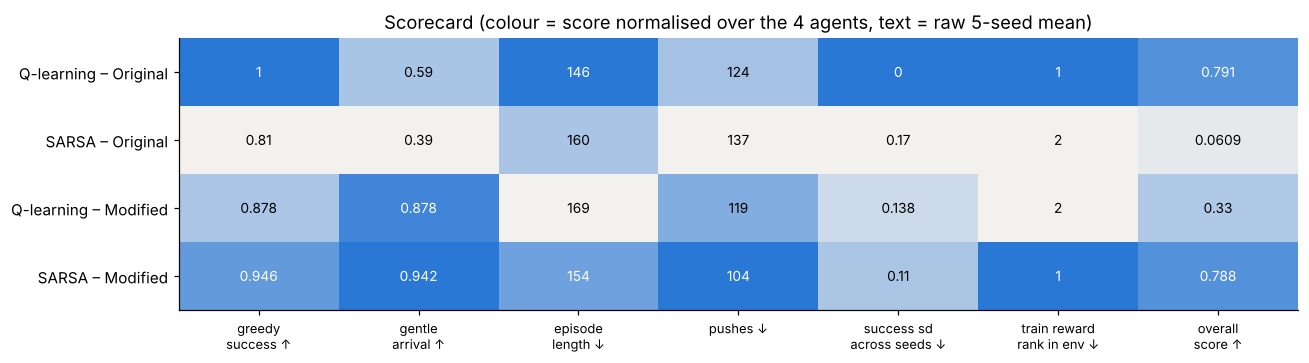

,,success,gentle,length,pushes,success_sd,train_reward_rank_in_env,overall
algo,env,,,,,,,
Q-learning,Original,1.000,0.362,1.000,0.385,1.000,1.0,0.791
SARSA,Original,0.000,0.000,0.365,0.000,0.000,0.0,0.061
Q-learning,Modified,0.358,0.884,0.000,0.555,0.186,0.0,0.330
SARSA,Modified,0.716,1.000,0.657,1.000,0.353,1.0,0.788


In [33]:
if RUN_EXTENDED:
    m = SEED_EVAL.groupby(["algo", "env"]).agg(success=("success_rate", "mean"), gentle=("gentle_arrival_rate", "mean"),
                                                length=("mean_episode_length", "mean"), pushes=("mean_pushes", "mean"),
                                                success_sd=("success_rate", "std"),
                                                train_reward=("train_reward_last1000", "mean"))
    m = m.loc[order]
    m["train_reward_rank_in_env"] = m.groupby(level="env")["train_reward"].rank(ascending=False)
    higher_better = dict(success=True, gentle=True, length=False, pushes=False, success_sd=False, train_reward_rank_in_env=False)
    crit = list(higher_better)
    score = pd.DataFrame(index=m.index)
    for c in crit:
        v = m[c].astype(float); rng_ = v.max() - v.min()
        s_ = (v - v.min()) / rng_ if rng_ > 0 else v * 0 + 1
        score[c] = s_ if higher_better[c] else 1 - s_
    score["overall"] = score[crit].mean(axis=1)

    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.imshow(score.values, cmap=LinearSegmentedColormap.from_list("sc", ["#f2f1ee", "#2a78d6"]), vmin=0, vmax=1, aspect="auto")
    raw = m[crit].copy(); raw["overall"] = score["overall"]
    for i in range(score.shape[0]):
        for j in range(score.shape[1]):
            ax.text(j, i, f"{raw.values[i, j]:.3g}", ha="center", va="center", fontsize=9,
                    color="white" if score.values[i, j] > 0.6 else "black")
    ax.set_xticks(range(score.shape[1])); ax.set_xticklabels(["greedy\nsuccess ↑", "gentle\narrival ↑", "episode\nlength ↓",
                                                              "pushes ↓", "success sd\nacross seeds ↓",
                                                              "train reward\nrank in env ↓", "overall\nscore ↑"], fontsize=8.5)
    ax.set_yticks(range(4)); ax.set_yticklabels([f"{a} – {e}" for a, e in order]); ax.grid(False)
    ax.set_title("Scorecard (colour = score normalised over the 4 agents, text = raw 5-seed mean)")
    plt.tight_layout(); plt.show()
    display(score.round(3))

**Interpretation.** The scorecard summarises the study in one picture, and it shows a clean **reversal**:

* in the **original** (noise-free, unshaped) environment, **Q-learning beats SARSA on all six criteria** (5-seed means): greedy success 1.00 vs 0.81, shorter episodes, fewer pushes, zero seed variance and the better training reward;
* in the **modified** (sticky, shaped) environment, **SARSA beats Q-learning on all six**: success 0.946 vs 0.878, gentle 0.94 vs 0.88, 154 vs 169 steps, 104 vs 119 pushes, a smaller seed spread and the better training reward.

The "overall" column is a plain average of the normalised criteria, which puts SARSA-modified (0.79) level with Q-learning-original (0.79). Individual comparisons are not statistically significant with five seeds (X.1.2). But the direction of the reversal is consistent and matches the theory discussed in e.4.

---
## (e) Discussion

### e.1 Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?
**Yes.** This is the most robust finding of the study.

* **Q-value plot, main seed (d.2):** Q-learning's average max Q is above SARSA's almost throughout training in both environments. The gap is about **50 % larger** in the modified environment (mean |gap| 1.76 vs 1.16). It stays near its peak of about 2–2.7 until episode 5 000, while the original gap shrinks after about 2 500 episodes.
* **Five seeds (X.1):** the modified gap is larger for **every seed**. The paired t-test gives a mean increase of +0.37 (p = 0.009). The mean curves separate after about episode 2 500 and stay separate (final gap about 1.1 vs about 0.5).
* **Where (d.9):** the extra disagreement concentrates in the final-approach band around v ≈ 0.04, where one blocked command decides between +20 and nothing. There the mean |V difference| rises from 2.6 to 4.1.

**Why:**

1. The sticky actuator adds transition noise that the agent cannot explain. The TD error is about 25–40 % higher in the modified environment (d.8). Noisier estimates inflate Q-learning's **maximisation bias**, since `max_a'` picks up positive errors, while SARSA's single sampled `a'` has no such bias.
2. **Exploration costs more.** An exploratory switch may get stuck, and every exploratory push costs 0.2. So the ε-greedy policy that SARSA evaluates is worse relative to the greedy policy than in the original environment.

The stickiness sweep (X.2) adds a refinement: the reward shaping alone (p = 0) already raises the gap somewhat (1.44 vs 1.16 for the same seed). So the increase comes partly from the energy penalty and bonus and partly from stickiness. The gap narrows as ε → 0.01, because SARSA's `a'` then almost always equals the greedy action.

### e.2 Why is the modified environment non-Markovian with respect to the observation, and how does it affect credit assignment?
The true state of the system is **(x, v, a_prev)**. For the same observation (x, v) and the same selected action "Right":

* if `a_prev = Right`, the car accelerates right with probability 1;
* if `a_prev = Left`, it still accelerates left with probability 0.2.

So `P(s' | x, v, a)` is not fixed. It depends on hidden history, including the agent's *own* earlier choices and how often its current policy switches. The Markov property fails with respect to the observation, which makes this a POMDP. The 20 × 20 binning adds further aliasing.

Effects on credit assignment:

* **Mis-attributed consequences.** When a change is blocked, the effect of `a_prev` is credited to the selected `a`. A good "Right" is sometimes blamed for a leftward move, which drags its Q-value towards the wrong action. That is part of the higher TD error in d.8.
* **Delayed, hidden influence.** Every decision also changes what the *next* step can execute. Holding a command is always reliable, and switching is not. That effect travels through a variable the Q-table cannot index, so it can only be averaged.
* **Policy-dependent targets.** The averaged transition model depends on the policy's switch rate, so the effective environment keeps changing while the agent learns. This slows convergence and makes the curves swing more.
* **Penalty vs effect mismatch.** The penalty follows the *selected* action, the dynamics the *executed* one. Selecting "None" while the actuator still pushes gives "free" thrust, which partly explains the larger "None" share in the modified policy maps.

**Evidence from X.3:** an oracle that sees `a_prev` chooses a *different* greedy action depending on the actuator state in 78 % of cells, so the hidden variable really does matter for the optimal decision. Within the same budget, though, the oracle learns far worse: tripling the table spreads the same experience too thinly. Under tabular learning, treating the problem as an aliased MDP is the more efficient choice. The price is the noisier, biased credit assignment described above.

### e.3 Do the energy penalty and gentle-arrival bonus encourage fewer pushes or a slower, more controlled arrival?
**Both**, and the agents also learn to switch less where a stuck switch would hurt.

* **Fewer pushes (d.4).** In the last 1 000 episodes the modified agents push on 66–69 % of steps (103–111 pushes per episode). The original agents push on 85–86 % (about 130), and their push share *rises* during training. The 5-seed means confirm this: 104–119 greedy pushes against 124–137.
* **Slower, controlled arrival (d.6, d.7, X.1).** The median arrival speed falls from 0.034–0.042 to 0.022–0.023. **100 %** of modified training arrivals are gentle, against 86 % and 26 % in the original. The 5-seed greedy gentle rate is 0.88–0.94 against 0.39–0.59, and in the original that rate varies wildly between seeds, so there gentleness is luck rather than learned.
* **Policy maps (d.5) and trajectories (d.11).** The "None" share doubles (23–27 % vs 11–16 %) and forms a coasting band just below the flag. The greedy trajectories visibly flatten the velocity curve onto the 0.04 line before x = 0.5. Blocked commands occur only at the swing's turning points and never on the final approach.
* **Trade-off.** The bonus is worth about 20 steps or 100 pushes, so trading a little speed for a gentle arrival is rational. Q-learning-modified pays about 15 extra steps, while SARSA-modified needs none (d.8).

### e.4 Which algorithm performs better under sticky actuators? Is this consistent with on-policy vs off-policy theory?
**SARSA performs better under sticky actuators, consistently but not decisively.** The comparison is the 5-seed mean ± std (X.1):

| Modified environment | Q-learning | SARSA |
|---|---|---|
| Greedy success / gentle rate | 0.878 ± 0.14 / 0.878 ± 0.14 | **0.946 ± 0.11 / 0.942 ± 0.11** |
| Greedy episode length / pushes | 168.5 / 118.8 | **153.6 / 104.4** |
| Training reward, last 1 000 episodes | −163.3 ± 6.0 | **−157.2 ± 11.3** |
| Action-switch rate (seed 42) | 0.249 | **0.213** |

SARSA is better on every criterion, and in the stickiness sweep its training performance is better or equal at every level of p (X.2). The differences are **not statistically significant** (p = 0.32–0.47, n = 5). In the clean original environment the ranking **reverses**: Q-learning wins on all six scorecard criteria (X.4).

**This is consistent with theory.**

* **Q-learning** is off-policy. It learns the values of the *greedy* policy and assumes every future command is executed as intended. In a clean, deterministic environment that is exactly right, and it converges to the faster optimal policy. That is why it wins in the original environment.
* **SARSA** is on-policy. It learns the values of what *actually* happens when the agent acts, including exploratory switches that get stuck and their energy cost. That makes it **risk-aware**, like the "safe path" in Cliff Walking. It switches less (d.8, X.2), suffers fewer blocked commands, and holds a steady command on the final approach. Its values are less over-optimistic (e.1), so its policy fits a noisy actuator better.

One caveat: from the agent's point of view stickiness is *environment* noise, not policy noise. As ε → 0.01 the two algorithms' targets converge, so a modest, non-significant advantage is exactly what theory predicts for this setting.

### e.5 One limitation and one improvement
**Limitation.** The experiments are limited by **sample budget and tabular representation**. With 6 000 episodes the value functions are still drifting (the average-max-Q curves are still falling at episode 6 000). A 20 × 20 grid cannot exploit extra information: the a_prev-aware oracle collapsed to 5–37 % success because each of its 3 600 states got too little experience. Statistical power is also limited. Even with five seeds, the Q-learning vs SARSA differences under sticky actuators remain non-significant, and the stickiness sweep uses a single seed per value of p.

**Improvement.** Replace the lookup table with a representation that **generalises across neighbouring states**, such as **tile coding** (several offset 20 × 20 grids) or a small neural network, while keeping the same ε schedule. Then train longer (for example 20 000 episodes) over 10 or more seeds, and report confidence intervals for every curve. That would allow a fair oracle comparison (a_prev as an extra input feature instead of a 3 × larger table) and a properly powered test of the on-policy vs off-policy difference.

### Run completed
This final cell prints the finishing timestamp, so the notebook's start and end times are both on record next to the virtual-lab screenshots.

In [34]:
print("Run finished at:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "| host:", socket.gethostname())

Run finished at: 2026-11-01 08:35:56 | host: vm


---
## Appendix – Virtual-lab execution screenshots
*(Insert the timestamped screenshots from the virtual lab here: the start-of-run cell (0.2), the training log (T.3) and the end-of-run cell above.)*